# Predicting Airline Flight Delays Using Apache Spark
### A Comparative Study of Machine Learning Classifiers (Logistic Regression, Random Forest, Gradient-Boosted Trees)

**Module:** M33877 Big Data and Machine Learning Applications (University of Portsmouth)
**Data:** U.S. Bureau of Transportation Statistics (BTS), *Reporting Carrier On-Time Performance*, January–December 2025 (12 monthly CSV files, ~3 GB)
**Task:** binary classification. `DELAYED = 1` if `ARR_DELAY >= 15` minutes, otherwise `0`.

**How to run (Google Colab):**
1. Put the 12 files in Google Drive at `MyDrive/BDMLA/FlightDelay2025/` (`2025_Jan.csv` … `2025_Dec.csv`).
2. `Runtime → Run all`. The notebook mounts Drive, installs Java 17 + PySpark if needed, and writes all outputs to `MyDrive/BDMLA/FlightDelay2025_outputs/`.
3. The expensive CSV→Parquet step is checkpointed to Drive, so if Colab disconnects you can re-run and it resumes from the Parquet copy.

**Leakage policy.** The model is meant to be usable *before departure* (e.g. the evening before, when the schedule is fixed). Columns are therefore taken from an **allow-list** at ingestion time. Anything recorded during or after the flight (`ARR_DELAY` apart from creating the label, `ARR_TIME`, `ACTUAL_ELAPSED_TIME`, `AIR_TIME`, `WHEELS_ON/OFF`, `TAXI_IN/OUT`, all `*_DELAY` cause columns, **and also `DEP_TIME`, `DEP_DELAY`, `DEP_DEL15`, `ARR_DEL15`**) is never loaded into the feature set.

> No results are hard-coded in this notebook. Every number in the report comes from the outputs this notebook writes.

## 1. Environment setup
Colab already has Python and (recent images) PySpark. We make sure Java 17+ and PySpark are available (installing PySpark 3.5 only if it is missing), then mount Google Drive.

In [4]:
import os, sys, subprocess, shutil, importlib

IS_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

def java_major_version():
    try:
        out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        token = out.split('"')[1]
        return int(token.split(".")[0]) if not token.startswith("1.") else int(token.split(".")[1])
    except Exception:
        return 0

if IS_COLAB and java_major_version() < 17:
    print("Installing OpenJDK 17 ...")
    subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jdk-headless > /dev/null", shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

if importlib.util.find_spec("pyspark") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.5"], check=True)

import pyspark
print("Java major version :", java_major_version())
print("PySpark version    :", pyspark.__version__)
print("Python version     :", sys.version.split()[0])

Java major version : 21
PySpark version    : 4.0.4
Python version     : 3.13.16


In [5]:
if IS_COLAB and os.path.exists("/content") and not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

## 2. Configuration
All paths and run-size switches live here. The defaults are sized for a **free Colab runtime (2 vCPU, ~12 GB RAM)**. If you have Colab Pro / a bigger machine, raise `TRAIN_SAMPLE_FRACTION` to `1.0`.

In [6]:
# RESUME: reuse the tuning results from my previous full run (skips ~1 hour of cross-validation)
RUN_BASELINE_MODELS = False
TUNED_PARAMS_OVERRIDE = {
    "Logistic Regression":    {"regParam": 0.0001, "elasticNetParam": 0.0},
    "Random Forest":          {"maxDepth": 12, "numTrees": 120},
    "Gradient-Boosted Trees": {"maxDepth": 6, "stepSize": 0.1},
}
CV_SCORES_OVERRIDE = {"Logistic Regression": 0.3693, "Random Forest": 0.4441, "Gradient-Boosted Trees": 0.4687}

In [7]:
import time, json, math, glob, functools, datetime as dt

# ---- paths -------------------------------------------------------------------
DRIVE_ROOT  = os.environ.get("BDMLA_DRIVE_ROOT", "/content/drive/MyDrive/BDMLA")
DATA_DIR    = os.environ.get("BDMLA_DATA_DIR",   f"{DRIVE_ROOT}/FlightDelay2025")
OUTPUT_DIR  = os.environ.get("BDMLA_OUTPUT_DIR", f"{DRIVE_ROOT}/FlightDelay2025_outputs")
LOCAL_WORK  = os.environ.get("BDMLA_LOCAL_WORK", "/content/work" if IS_COLAB else "./work")
FIG_DIR     = f"{OUTPUT_DIR}/figures"
TABLE_DIR   = f"{OUTPUT_DIR}/tables"
MODEL_DIR   = f"{OUTPUT_DIR}/models"
for d in (OUTPUT_DIR, FIG_DIR, TABLE_DIR, MODEL_DIR, LOCAL_WORK):
    os.makedirs(d, exist_ok=True)

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
FILES  = [f"{DATA_DIR}/2025_{m}.csv" for m in MONTHS]

# ---- run-size switches -------------------------------------------------------
SEED                   = 42
DELAY_THRESHOLD_MIN    = 15      # BTS definition of a delayed arrival
SPLIT_WEIGHTS          = [0.70, 0.10, 0.20]   # train / validation / test
TRAIN_SAMPLE_FRACTION  = float(os.environ.get("BDMLA_TRAIN_FRACTION", 0.30))  # share of the training split used to fit models
TE_SMOOTHING           = 100     # target-encoding smoothing strength (pseudo-count)
USE_CLASS_WEIGHTS      = True    # re-weight the minority class during training
RUN_TUNING             = os.environ.get("BDMLA_RUN_TUNING", "1") == "1"   # k-fold CrossValidator
TUNING_SAMPLE_FRACTION = float(os.environ.get("BDMLA_TUNING_FRACTION", 0.05))  # of the training split
CV_FOLDS               = 3
RUN_TEMPORAL_HOLDOUT   = os.environ.get("BDMLA_RUN_TEMPORAL", "1") == "1"  # train Jan–Sep, test Oct–Dec
RUN_SCALING_EXPERIMENT = os.environ.get("BDMLA_RUN_SCALING", "1") == "1"   # local[1] vs local[*]
SAVE_MODELS            = True
RUN_BASELINE_MODELS    = True    # fit the default-configuration models before tuning (section 13.1-13.3)
# Resume option: paste the best parameters from an earlier run's tuning output to skip CrossValidator
# entirely (saves roughly an hour on free Colab), e.g. {"Random Forest": {"maxDepth": 12, "numTrees": 120}, ...}
TUNED_PARAMS_OVERRIDE  = None
CV_SCORES_OVERRIDE     = None    # optional {model: best CV PR-AUC} from that earlier run, used in the report
FORCE_REBUILD_PARQUET  = False

missing = [f for f in FILES if not os.path.exists(f)]
print("Data folder :", DATA_DIR)
print("Files found :", len(FILES) - len(missing), "/ 12")
if missing:
    raise FileNotFoundError("Missing input files:\n  " + "\n  ".join(missing))
for f in FILES:
    print(f"  {os.path.basename(f):<14} {os.path.getsize(f) / 1e6:8.1f} MB")
print(f"Total size  : {sum(os.path.getsize(f) for f in FILES) / 1e9:.2f} GB")

Data folder : /content/drive/MyDrive/BDMLA/FlightDelay2025
Files found : 12 / 12
  2025_Jan.csv      243.2 MB
  2025_Feb.csv      228.2 MB
  2025_Mar.csv      271.6 MB
  2025_Apr.csv      264.1 MB
  2025_May.csv      274.3 MB
  2025_Jun.csv      277.4 MB
  2025_Jul.csv      286.2 MB
  2025_Aug.csv      272.7 MB
  2025_Sep.csv      254.1 MB
  2025_Oct.csv      274.7 MB
  2025_Nov.csv      258.1 MB
  2025_Dec.csv      264.5 MB
Total size  : 3.17 GB


## 3. Spark configuration
Colab is a single machine, so Spark runs in **local mode** with one executor thread per core. The settings below matter for this data size:
* **Driver memory** is set to ~60% of the machine's RAM (in local mode the driver *is* the executor).
* **Adaptive Query Execution (AQE)** re-plans shuffles at runtime and coalesces small partitions.
* **Shuffle partitions** are lowered from the default 200 (designed for clusters) to a few per core, which avoids hundreds of tiny tasks.
* **Kryo** serialisation is faster and more compact than Java serialisation.
* **Arrow** is switched off: only small aggregates are collected for plotting, so it gains little, and it avoids Arrow/JDK compatibility problems.

In [8]:
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql import types as T

def total_ram_gb():
    try:
        return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
    except (ValueError, OSError, AttributeError):
        return 8.0

N_CORES       = os.cpu_count() or 2
DRIVER_MEM_GB = max(2, int(total_ram_gb() * 0.6))
SHUFFLE_PARTS = max(8, N_CORES * 4)

def build_spark(master=f"local[{N_CORES}]", app="BDMLA-FlightDelay-2025"):
    return (SparkSession.builder
            .appName(app)
            .master(master)
            .config("spark.driver.memory", f"{DRIVER_MEM_GB}g")
            .config("spark.driver.maxResultSize", "2g")
            .config("spark.sql.shuffle.partitions", str(SHUFFLE_PARTS))
            .config("spark.sql.adaptive.enabled", "true")
            .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
            .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
            .config("spark.sql.execution.arrow.pyspark.enabled", "false")
            .config("spark.sql.legacy.timeParserPolicy", "CORRECTED")
            .config("spark.ui.showConsoleProgress", "false")
            .getOrCreate())

spark = build_spark()
spark.sparkContext.setLogLevel("ERROR")
print("Spark version        :", spark.version)
print("Master               :", spark.sparkContext.master)
print("Default parallelism  :", spark.sparkContext.defaultParallelism)
print("Driver memory        :", f"{DRIVER_MEM_GB} GB")
print("Shuffle partitions   :", SHUFFLE_PARTS)
print("Spark UI             :", spark.sparkContext.uiWebUrl)

Spark version        : 4.0.4
Master               : local[2]
Default parallelism  : 2
Driver memory        : 8 GB
Shuffle partitions   : 8
Spark UI             : http://44222a7e7613:4040


### Plot style
One consistent style for every figure: thin marks, light grid, a fixed colour per model (Logistic Regression = blue, Random Forest = orange, GBT = aqua) so the same model has the same colour in every chart.

In [9]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
NEUTRAL  = "#2a78d6"
ON_TIME_C, DELAYED_C = "#2a78d6", "#eb6834"
MODEL_COLORS = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834", "Gradient-Boosted Trees": "#1baf7a",
                "Majority baseline": "#8a8984"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 2,
})

def save_fig(fig, name):
    path = f"{FIG_DIR}/{name}.png"
    fig.savefig(path)
    plt.show()
    plt.close(fig)
    print("saved", path)

def human(v, _=None):
    v = float(v)
    for unit, div in (("M", 1e6), ("K", 1e3)):
        if abs(v) >= div:
            return f"{v / div:.1f}{unit}".replace(".0" + unit, unit)
    return f"{v:.0f}"
COUNT_FMT = matplotlib.ticker.FuncFormatter(human)

def pct_axis(ax, axis="y"):
    fmt = matplotlib.ticker.PercentFormatter(1.0, decimals=0)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

## 4. Ingestion: read all 12 CSV files and union them
BTS exports come in two naming styles (`ARR_DELAY` from the custom download page, `ArrDelay` from the pre-zipped files), and the pre-zipped files have a trailing comma that creates an empty extra column. To be robust to both, every header is **normalised** (lower-case, letters and digits only) and mapped to one canonical name.

Only the columns on the allow-list below are kept. This is the first line of defence against target leakage: post-flight columns never even enter the DataFrame (except `ARR_DELAY`, which is needed to build the label and is dropped straight after).

Every file is read with `inferSchema=False`. Schema inference would need an extra full pass over 3 GB of CSV, and we cast the few columns we need explicitly anyway.

In [10]:
import re

# canonical name -> accepted aliases (normalised: lower-case alphanumerics), in priority order
COLUMN_ALIASES = {
    "YEAR":              ["year"],
    "MONTH":             ["month"],
    "DAY_OF_MONTH":      ["dayofmonth"],
    "DAY_OF_WEEK":       ["dayofweek"],
    "FL_DATE":           ["fldate", "flightdate"],
    "REPORTING_AIRLINE": ["reportingairline", "opuniquecarrier", "opcarrier", "uniquecarrier", "iatacodereportingairline"],
    "FLIGHT_NUM":        ["flightnumberreportingairline", "opcarrierflnum", "flnum", "flightnum"],
    "TAIL_NUM":          ["tailnum", "tailnumber"],
    "ORIGIN":            ["origin"],
    "DEST":              ["dest"],
    "CRS_DEP_TIME":      ["crsdeptime"],
    "CRS_ARR_TIME":      ["crsarrtime"],
    "CRS_ELAPSED_TIME":  ["crselapsedtime"],
    "DISTANCE":          ["distance"],
    "CANCELLED":         ["cancelled"],
    "DIVERTED":          ["diverted"],
    "ARR_DELAY":         ["arrdelay"],          # label source only, dropped after labelling
}
REQUIRED = ["MONTH", "DAY_OF_WEEK", "REPORTING_AIRLINE", "ORIGIN", "DEST", "CRS_DEP_TIME", "CRS_ARR_TIME",
            "CRS_ELAPSED_TIME", "DISTANCE", "CANCELLED", "DIVERTED", "ARR_DELAY"]

# Columns that must never be used as features (known only during/after the flight)
LEAKAGE_COLUMNS = {"ARR_DELAY", "ARR_DELAY_NEW", "ARR_DEL15", "ARR_TIME", "ACTUAL_ELAPSED_TIME", "AIR_TIME",
                   "WHEELS_ON", "WHEELS_OFF", "TAXI_IN", "TAXI_OUT", "DEP_TIME", "DEP_DELAY", "DEP_DELAY_NEW",
                   "DEP_DEL15", "CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY",
                   "LATE_AIRCRAFT_DELAY", "CANCELLATION_CODE", "DELAYED"}

def normalise(name):
    return re.sub(r"[^a-z0-9]", "", name.lower())

def map_columns(raw_columns):
    lookup = {normalise(c): c for c in raw_columns}
    mapping = {}
    for canonical, aliases in COLUMN_ALIASES.items():
        for a in aliases:
            if a in lookup:
                mapping[canonical] = lookup[a]
                break
    return mapping

def read_month(path):
    raw = (spark.read
           .option("header", True)
           .option("inferSchema", False)
           .option("mode", "PERMISSIVE")
           .csv(path))
    mapping = map_columns(raw.columns)
    absent = [c for c in REQUIRED if c not in mapping]
    if absent:
        raise ValueError(f"{os.path.basename(path)} is missing required columns {absent}. Found: {raw.columns[:20]}...")
    if "FL_DATE" not in mapping and "DAY_OF_MONTH" not in mapping:
        raise ValueError(f"{os.path.basename(path)} needs either FL_DATE or DAY_OF_MONTH")
    cols = [F.col(f"`{src}`").alias(canon) for canon, src in mapping.items()]
    for canon in COLUMN_ALIASES:                      # keep a fixed schema across files
        if canon not in mapping:
            cols.append(F.lit(None).cast("string").alias(canon))
    return raw.select(*cols).withColumn("SOURCE_FILE", F.lit(os.path.basename(path))), len(raw.columns)

monthly = []
for f in FILES:
    df_m, n_raw_cols = read_month(f)
    monthly.append(df_m)
print(f"Each raw file has {n_raw_cols} columns; {len(COLUMN_ALIASES)} allow-listed columns are kept.")

raw_union = functools.reduce(lambda a, b: a.unionByName(b), monthly)
print("Unioned DataFrame schema (all strings at this point):")
raw_union.printSchema()

Each raw file has 110 columns; 17 allow-listed columns are kept.
Unioned DataFrame schema (all strings at this point):
root
 |-- YEAR: string (nullable = true)
 |-- MONTH: string (nullable = true)
 |-- DAY_OF_MONTH: string (nullable = true)
 |-- DAY_OF_WEEK: string (nullable = true)
 |-- FL_DATE: string (nullable = true)
 |-- REPORTING_AIRLINE: string (nullable = true)
 |-- FLIGHT_NUM: string (nullable = true)
 |-- TAIL_NUM: string (nullable = true)
 |-- ORIGIN: string (nullable = true)
 |-- DEST: string (nullable = true)
 |-- CRS_DEP_TIME: string (nullable = true)
 |-- CRS_ARR_TIME: string (nullable = true)
 |-- CRS_ELAPSED_TIME: string (nullable = true)
 |-- DISTANCE: string (nullable = true)
 |-- CANCELLED: string (nullable = true)
 |-- DIVERTED: string (nullable = true)
 |-- ARR_DELAY: string (nullable = true)
 |-- SOURCE_FILE: string (nullable = false)



### 4.1 Type casting and Parquet checkpoint
The union is cast to proper types and written once to **Parquet** (columnar, compressed, splittable). Every later step reads the Parquet copy instead of re-parsing 3 GB of text. This is the most important single optimisation in the notebook. A copy is backed up to Drive so a disconnected Colab session can resume here.

Times such as `CRS_DEP_TIME` are stored by BTS as `hhmm` (e.g. `1345`). They are converted to *minutes after midnight* so they can be used numerically.

In [11]:
def hhmm_to_minutes(col):
    t = F.col(col).cast("double").cast("int")
    t = F.when(t == 2400, 0).otherwise(t)
    return (F.floor(t / 100) * 60 + (t % 100)).cast("int")

def to_flag(col):
    return (F.col(col).cast("double") == 1.0).cast("int")

date_expr = F.coalesce(
    F.make_date(F.col("YEAR").cast("int"), F.col("MONTH").cast("int"), F.col("DAY_OF_MONTH").cast("int")),
    F.to_date(F.substring(F.col("FL_DATE"), 1, 10), "yyyy-MM-dd"),
    F.to_date(F.split(F.col("FL_DATE"), " ").getItem(0), "M/d/yyyy"),
)

typed = (raw_union
         .withColumn("FLIGHT_DATE", date_expr)
         .select(
             "FLIGHT_DATE",
             F.month("FLIGHT_DATE").alias("MONTH"),
             F.dayofmonth("FLIGHT_DATE").alias("DAY_OF_MONTH"),
             F.col("DAY_OF_WEEK").cast("int").alias("DAY_OF_WEEK"),       # BTS: 1 = Monday ... 7 = Sunday
             F.trim("REPORTING_AIRLINE").alias("REPORTING_AIRLINE"),
             F.trim("FLIGHT_NUM").alias("FLIGHT_NUM"),
             F.nullif(F.trim("TAIL_NUM"), F.lit("")).alias("TAIL_NUM"),
             F.trim("ORIGIN").alias("ORIGIN"),
             F.trim("DEST").alias("DEST"),
             hhmm_to_minutes("CRS_DEP_TIME").alias("CRS_DEP_MIN"),
             hhmm_to_minutes("CRS_ARR_TIME").alias("CRS_ARR_MIN"),
             F.col("CRS_ELAPSED_TIME").cast("double").alias("CRS_ELAPSED_TIME"),
             F.col("DISTANCE").cast("double").alias("DISTANCE"),
             to_flag("CANCELLED").alias("CANCELLED"),
             to_flag("DIVERTED").alias("DIVERTED"),
             F.col("ARR_DELAY").cast("double").alias("ARR_DELAY"),
             "SOURCE_FILE"))

STAGED_LOCAL = f"{LOCAL_WORK}/staged_2025.parquet"
STAGED_DRIVE = f"{OUTPUT_DIR}/staged_2025.parquet"

if FORCE_REBUILD_PARQUET or not os.path.exists(STAGED_LOCAL):
    if not FORCE_REBUILD_PARQUET and os.path.exists(f"{STAGED_DRIVE}/_SUCCESS"):
        print("Restoring Parquet checkpoint from Drive ...")
        shutil.copytree(STAGED_DRIVE, STAGED_LOCAL, dirs_exist_ok=True)
    else:
        t0 = time.time()
        typed.write.mode("overwrite").parquet(STAGED_LOCAL)
        csv_to_parquet_s = time.time() - t0
        print(f"CSV -> Parquet conversion took {csv_to_parquet_s:.1f} s")
        if os.path.abspath(STAGED_LOCAL) != os.path.abspath(STAGED_DRIVE):
            shutil.copytree(STAGED_LOCAL, STAGED_DRIVE, dirs_exist_ok=True)

staged = spark.read.parquet(STAGED_LOCAL)
staged.printSchema()

def dir_size_mb(path):
    return sum(os.path.getsize(p) for p in glob.glob(f"{path}/**", recursive=True) if os.path.isfile(p)) / 1e6
print(f"CSV size     : {sum(os.path.getsize(f) for f in FILES) / 1e6:,.0f} MB")
print(f"Parquet size : {dir_size_mb(STAGED_LOCAL):,.0f} MB (allow-listed columns only)")

Restoring Parquet checkpoint from Drive ...
root
 |-- FLIGHT_DATE: date (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- DAY_OF_MONTH: integer (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- REPORTING_AIRLINE: string (nullable = true)
 |-- FLIGHT_NUM: string (nullable = true)
 |-- TAIL_NUM: string (nullable = true)
 |-- ORIGIN: string (nullable = true)
 |-- DEST: string (nullable = true)
 |-- CRS_DEP_MIN: integer (nullable = true)
 |-- CRS_ARR_MIN: integer (nullable = true)
 |-- CRS_ELAPSED_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- CANCELLED: integer (nullable = true)
 |-- DIVERTED: integer (nullable = true)
 |-- ARR_DELAY: double (nullable = true)
 |-- SOURCE_FILE: string (nullable = true)

CSV size     : 3,169 MB
Parquet size : 61 MB (allow-listed columns only)


### 4.2 Rows per monthly file and a CSV-vs-Parquet scan benchmark
The benchmark runs the same aggregation (delay rate per carrier) against the raw CSV union and against the Parquet copy. It gives a concrete number for the report on why the columnar format is used.

In [12]:
rows_per_file = (staged.groupBy("SOURCE_FILE").count()
                 .withColumn("m", F.to_date(F.concat(F.lit("2025-"), F.substring("SOURCE_FILE", 6, 3), F.lit("-01")), "yyyy-MMM-dd"))
                 .orderBy("m").drop("m").toPandas())
rows_per_file.to_csv(f"{TABLE_DIR}/rows_per_file.csv", index=False)
print(rows_per_file.to_string(index=False))
print(f"\nTotal flights (raw, all 12 files): {rows_per_file['count'].sum():,}")

def bench(df):
    t0 = time.time()
    (df.where(F.col("ARR_DELAY").isNotNull())
       .groupBy("REPORTING_AIRLINE")
       .agg(F.avg((F.col("ARR_DELAY").cast("double") >= 15).cast("int")).alias("rate"))
       .collect())
    return time.time() - t0

csv_s, parquet_s = bench(raw_union), bench(staged)
benchmark = pd.DataFrame({"source": ["CSV (12 files)", "Parquet"], "seconds": [csv_s, parquet_s]})
benchmark.to_csv(f"{TABLE_DIR}/csv_vs_parquet_benchmark.csv", index=False)
print(benchmark.to_string(index=False))
print(f"Parquet speed-up: {csv_s / parquet_s:.1f}x")

 SOURCE_FILE  count
2025_Jan.csv 539747
2025_Feb.csv 504884
2025_Mar.csv 600872
2025_Apr.csv 583950
2025_May.csv 605648
2025_Jun.csv 611575
2025_Jul.csv 631428
2025_Aug.csv 602378
2025_Sep.csv 562439
2025_Oct.csv 605844
2025_Nov.csv 570550
2025_Dec.csv 582304

Total flights (raw, all 12 files): 7,001,619
        source   seconds
CSV (12 files) 79.825393
       Parquet  3.177937
Parquet speed-up: 25.1x


## 5. Data quality profile (before cleaning)

In [13]:
n_raw = staged.count()
profile_cols = ["FLIGHT_DATE", "REPORTING_AIRLINE", "TAIL_NUM", "ORIGIN", "DEST", "CRS_DEP_MIN", "CRS_ARR_MIN",
                "CRS_ELAPSED_TIME", "DISTANCE", "ARR_DELAY"]
null_counts = staged.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in profile_cols]).toPandas().T
null_counts.columns = ["null_rows"]
null_counts["null_pct"] = null_counts["null_rows"] / n_raw
status = staged.agg(F.sum("CANCELLED").alias("cancelled"), F.sum("DIVERTED").alias("diverted")).first()

null_counts.to_csv(f"{TABLE_DIR}/null_profile.csv")
print(f"Raw rows       : {n_raw:,}")
print(f"Cancelled      : {status['cancelled']:,} ({status['cancelled'] / n_raw:.2%})")
print(f"Diverted       : {status['diverted']:,} ({status['diverted'] / n_raw:.2%})")
print(null_counts.assign(null_pct=null_counts["null_pct"].map("{:.3%}".format)).to_string())

print("\nARR_DELAY distribution (minutes):")
print(staged.select(F.percentile_approx("ARR_DELAY", [0.01, 0.25, 0.5, 0.75, 0.9, 0.99]).alias("p")).first()["p"])

Raw rows       : 7,001,619
Cancelled      : 102,876 (1.47%)
Diverted       : 19,258 (0.28%)
                   null_rows null_pct
FLIGHT_DATE                0   0.000%
REPORTING_AIRLINE          0   0.000%
TAIL_NUM               12501   0.179%
ORIGIN                     0   0.000%
DEST                       0   0.000%
CRS_DEP_MIN                0   0.000%
CRS_ARR_MIN                0   0.000%
CRS_ELAPSED_TIME           2   0.000%
DISTANCE                   0   0.000%
ARR_DELAY             122135   1.744%

ARR_DELAY distribution (minutes):
[-37.0, -15.0, -6.0, 11.0, 48.0, 225.0]


## 6. Schedule-context features (computed on the *full* schedule, before cleaning)
These features describe what the published schedule looks like around a flight. Every one is known in advance:
* **Airport congestion:** how many departures are scheduled from the origin in the same hour, how many arrivals at the destination, and how busy the origin and carrier are that day.
* **Aircraft rotation:** which leg of the day this is for the aircraft (tail number), and the *scheduled* turnaround time since its previous leg's scheduled arrival. Delays propagate along an aircraft's rotation, so late legs with tight turnarounds should be riskier.

**Why before cleaning?** A flight that is later cancelled was still part of the schedule the night before. If these counts were taken *after* removing cancellations, a disrupted day (storms, outages) would show fewer flights, so the feature would quietly encode the outcome. That is a subtle form of leakage, and computing on the full schedule avoids it.

In [14]:
base = (staged
        .where(F.col("FLIGHT_DATE").isNotNull() & F.col("CRS_DEP_MIN").isNotNull())
        .withColumn("DEP_HOUR", (F.col("CRS_DEP_MIN") / 60).cast("int"))
        .withColumn("ARR_HOUR", (F.col("CRS_ARR_MIN") / 60).cast("int")))

w_origin_hour = Window.partitionBy("ORIGIN", "FLIGHT_DATE", "DEP_HOUR")
w_dest_hour   = Window.partitionBy("DEST", "FLIGHT_DATE", "ARR_HOUR")
w_origin_day  = Window.partitionBy("ORIGIN", "FLIGHT_DATE")
w_carrier_day = Window.partitionBy("REPORTING_AIRLINE", "FLIGHT_DATE")
w_tail        = Window.partitionBy("TAIL_NUM", "FLIGHT_DATE").orderBy("CRS_DEP_MIN")

prev_arr = F.lag("CRS_ARR_MIN").over(w_tail)
prev_dep = F.lag("CRS_DEP_MIN").over(w_tail)
turnaround = F.when(prev_arr.isNull() | (prev_arr < prev_dep), None).otherwise(F.col("CRS_DEP_MIN") - prev_arr)

with_schedule = (base
    .withColumn("ORIGIN_HOURLY_DEPS",    F.count(F.lit(1)).over(w_origin_hour))
    .withColumn("DEST_HOURLY_ARRS",      F.count(F.lit(1)).over(w_dest_hour))
    .withColumn("ORIGIN_DAILY_DEPS",     F.count(F.lit(1)).over(w_origin_day))
    .withColumn("CARRIER_DAILY_FLIGHTS", F.count(F.lit(1)).over(w_carrier_day))
    .withColumn("TAIL_LEG_OF_DAY", F.when(F.col("TAIL_NUM").isNotNull(), F.row_number().over(w_tail)))
    .withColumn("SCHED_TURNAROUND_MIN", F.when(F.col("TAIL_NUM").isNotNull(), turnaround)))

## 7. Data cleaning and label creation
Cleaning rules, in order (each step is counted so the report can show a cleaning funnel):
1. remove **cancelled** flights (no arrival, so no label);
2. remove **diverted** flights (they never arrived at the scheduled destination);
3. remove rows where **`ARR_DELAY` is null**;
4. remove **duplicate** flight records (same date, carrier, flight number, origin, destination, scheduled departure);
5. remove **invalid schedule values** (non-positive scheduled duration or distance, missing airport/carrier codes).

The label is then `DELAYED = 1 if ARR_DELAY >= 15`, and `ARR_DELAY` is dropped immediately so it cannot leak into the features.

In [15]:
funnel = [("Raw flights (12 files)", n_raw)]

step = with_schedule.where(F.col("CANCELLED") == 0)
funnel.append(("Remove cancelled", step.count()))
step = step.where(F.col("DIVERTED") == 0)
funnel.append(("Remove diverted", step.count()))
step = step.where(F.col("ARR_DELAY").isNotNull())
funnel.append(("Remove null ARR_DELAY", step.count()))
step = step.dropDuplicates(["FLIGHT_DATE", "REPORTING_AIRLINE", "FLIGHT_NUM", "ORIGIN", "DEST", "CRS_DEP_MIN"])
funnel.append(("Remove duplicates", step.count()))
step = step.where((F.col("CRS_ELAPSED_TIME") > 0) & (F.col("DISTANCE") > 0) & F.col("CRS_ARR_MIN").isNotNull()
                  & F.col("ORIGIN").isNotNull() & F.col("DEST").isNotNull() & F.col("REPORTING_AIRLINE").isNotNull())
funnel.append(("Remove invalid schedule values", step.count()))

clean = (step
         .withColumn("DELAYED", (F.col("ARR_DELAY") >= DELAY_THRESHOLD_MIN).cast("int"))
         .drop("ARR_DELAY", "CANCELLED", "DIVERTED"))

funnel_df = pd.DataFrame(funnel, columns=["step", "rows"])
funnel_df["removed"] = (-funnel_df["rows"].diff()).fillna(0).astype(int)
funnel_df["pct_of_raw"] = funnel_df["rows"] / n_raw
funnel_df.to_csv(f"{TABLE_DIR}/cleaning_funnel.csv", index=False)
print(funnel_df.to_string(index=False))

                          step    rows  removed  pct_of_raw
        Raw flights (12 files) 7001619        0    1.000000
              Remove cancelled 6898743   102876    0.985307
               Remove diverted 6879485    19258    0.982556
         Remove null ARR_DELAY 6879484        1    0.982556
             Remove duplicates 6879484        0    0.982556
Remove invalid schedule values 6879483        1    0.982556


### 7.1 Final row-level features
* calendar: `MONTH`, `DAY_OF_MONTH`, `DAY_OF_WEEK`, `IS_WEEKEND`, and cyclical sin/cos encodings for month and departure hour (so that 23:00 is "close to" 00:00 for the linear model);
* **holiday proximity**: number of days to the nearest U.S. federal holiday (holiday travel peaks are known well in advance);
* route identifier `ORIGIN_DEST` (later target-encoded) and an `ORIGIN_HOUR` interaction.

The result is written to Parquet once more, so modelling starts from a compact, fully prepared table.

In [16]:
HOLIDAYS = ["2024-12-25", "2025-01-01", "2025-01-20", "2025-02-17", "2025-05-26", "2025-06-19", "2025-07-04",
            "2025-09-01", "2025-10-13", "2025-11-11", "2025-11-27", "2025-12-25", "2026-01-01"]
hol = spark.createDataFrame([(h,) for h in HOLIDAYS], ["H"]).select(F.to_date("H").alias("H"))
date_hol = (clean.select("FLIGHT_DATE").distinct()
            .crossJoin(hol)
            .groupBy("FLIGHT_DATE")
            .agg(F.min(F.abs(F.datediff("FLIGHT_DATE", "H"))).alias("DAYS_TO_HOLIDAY")))

TWO_PI = 2 * math.pi
features_df = (clean
    .join(F.broadcast(date_hol), "FLIGHT_DATE", "left")
    .withColumn("IS_WEEKEND", F.col("DAY_OF_WEEK").isin(6, 7).cast("int"))
    .withColumn("DEP_HOUR_SIN", F.sin(TWO_PI * F.col("CRS_DEP_MIN") / 1440))
    .withColumn("DEP_HOUR_COS", F.cos(TWO_PI * F.col("CRS_DEP_MIN") / 1440))
    .withColumn("MONTH_SIN", F.sin(TWO_PI * (F.col("MONTH") - 1) / 12))
    .withColumn("MONTH_COS", F.cos(TWO_PI * (F.col("MONTH") - 1) / 12))
    .withColumn("HAS_PREV_LEG", F.col("SCHED_TURNAROUND_MIN").isNotNull().cast("int"))
    .withColumn("SCHED_TURNAROUND_MIN",
                F.greatest(F.least(F.coalesce(F.col("SCHED_TURNAROUND_MIN"), F.lit(720)), F.lit(720)), F.lit(0)).cast("double"))
    .withColumn("TAIL_LEG_OF_DAY", F.coalesce(F.col("TAIL_LEG_OF_DAY"), F.lit(1)).cast("double"))
    .withColumn("ROUTE", F.concat_ws("_", "ORIGIN", "DEST"))
    .withColumn("ORIGIN_HOUR", F.concat_ws("_", "ORIGIN", F.col("DEP_HOUR").cast("string")))
    .withColumn("CARRIER_ORIGIN", F.concat_ws("_", "REPORTING_AIRLINE", "ORIGIN")))

PREPARED = f"{LOCAL_WORK}/prepared_2025.parquet"
t0 = time.time()
features_df.write.mode("overwrite").parquet(PREPARED)
print(f"Feature table written in {time.time() - t0:.1f} s")
data = spark.read.parquet(PREPARED).cache()
n_clean = data.count()
print(f"Modelling rows: {n_clean:,}  |  columns: {len(data.columns)}")
assert "ARR_DELAY" not in data.columns

Feature table written in 332.5 s
Modelling rows: 6,879,483  |  columns: 33


## 8. Exploratory data analysis
All aggregations run in Spark and only the small summary tables are brought back to pandas for plotting.

 DELAYED   count    share
       0 5344846 0.776926
       1 1534637 0.223074
Delayed share = 22.31%. A model that always predicts 'on time' would score 77.69% accuracy with zero recall.


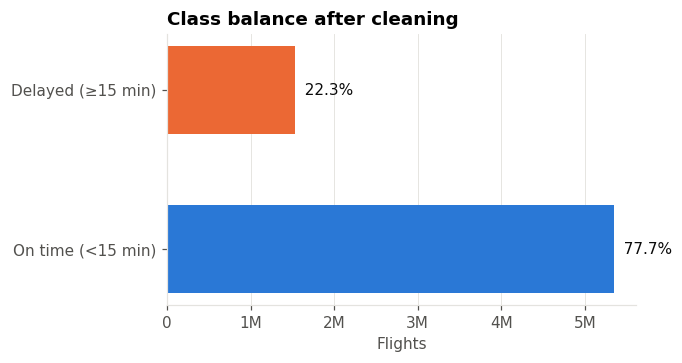

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/01_class_balance.png


In [17]:
class_counts = data.groupBy("DELAYED").count().orderBy("DELAYED").toPandas()
class_counts["share"] = class_counts["count"] / class_counts["count"].sum()
class_counts.to_csv(f"{TABLE_DIR}/class_balance.csv", index=False)
POS_RATE = float(class_counts.loc[class_counts.DELAYED == 1, "share"].iloc[0])
print(class_counts.to_string(index=False))
print(f"Delayed share = {POS_RATE:.2%}. A model that always predicts 'on time' would score {1 - POS_RATE:.2%} accuracy with zero recall.")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
labels = ["On time (<15 min)", "Delayed (≥15 min)"]
bars = ax.barh(labels, class_counts["count"], color=[ON_TIME_C, DELAYED_C], height=0.55)
for b, s in zip(bars, class_counts["share"]):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {s:.1%}", va="center", color=INK)
ax.set_xlabel("Flights")
ax.xaxis.set_major_formatter(COUNT_FMT)
ax.set_title("Class balance after cleaning")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_class_balance")

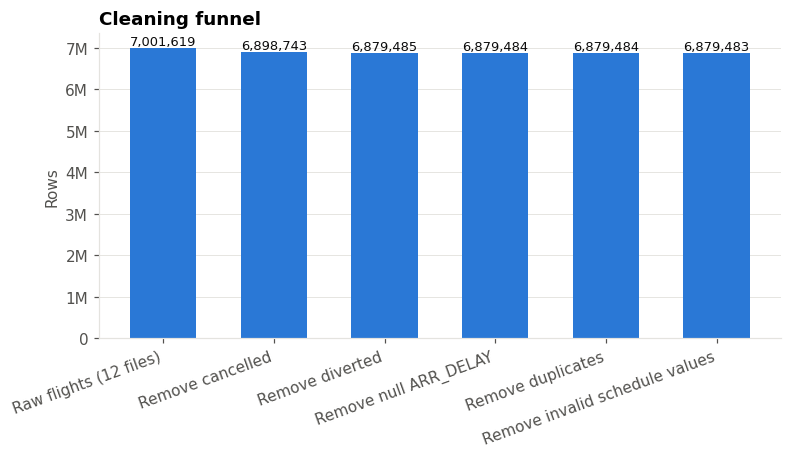

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/02_cleaning_funnel.png


In [18]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(funnel_df["step"], funnel_df["rows"], color=NEUTRAL, width=0.6)
for i, r in funnel_df.iterrows():
    ax.text(i, r["rows"], f"{r['rows']:,}", ha="center", va="bottom", fontsize=8.5, color=INK)
ax.set_ylabel("Rows")
ax.yaxis.set_major_formatter(COUNT_FMT)
ax.set_title("Cleaning funnel")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.grid(axis="x", visible=False)
save_fig(fig, "02_cleaning_funnel")

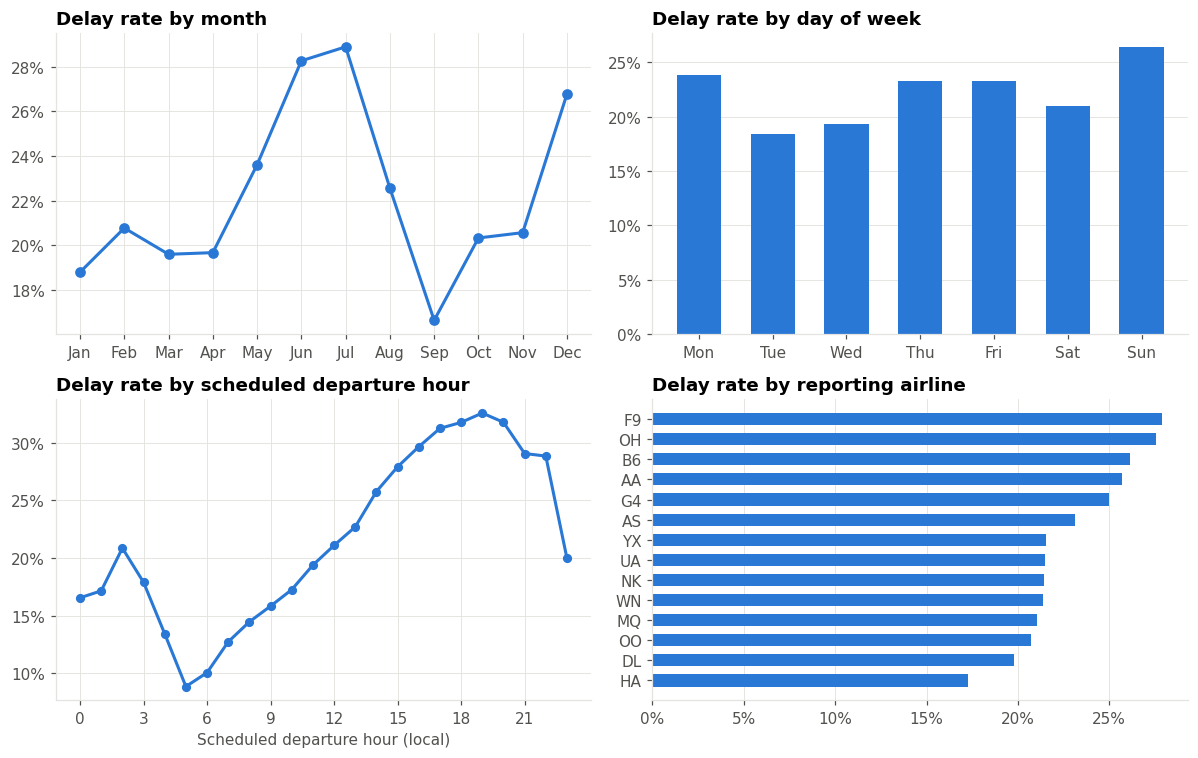

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/03_delay_rate_patterns.png


In [19]:
def rate_by(col, order_col=None, min_flights=0):
    out = (data.groupBy(col).agg(F.count("*").alias("flights"), F.avg("DELAYED").alias("delay_rate"))
           .where(F.col("flights") >= min_flights))
    return out.orderBy(order_col if order_col is not None else col).toPandas()

by_month = rate_by("MONTH")
by_dow   = rate_by("DAY_OF_WEEK")
by_hour  = rate_by("DEP_HOUR")
by_carr  = rate_by("REPORTING_AIRLINE", order_col=F.desc("delay_rate"))
for name, t in [("month", by_month), ("day_of_week", by_dow), ("dep_hour", by_hour), ("carrier", by_carr)]:
    t.to_csv(f"{TABLE_DIR}/delay_rate_by_{name}.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
ax = axes[0, 0]
ax.plot(by_month["MONTH"], by_month["delay_rate"], marker="o", color=NEUTRAL, markersize=6)
ax.set_xticks(range(1, 13), MONTHS); ax.set_title("Delay rate by month"); pct_axis(ax)
ax = axes[0, 1]
ax.bar(by_dow["DAY_OF_WEEK"], by_dow["delay_rate"], color=NEUTRAL, width=0.6)
ax.set_xticks(range(1, 8), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); ax.set_title("Delay rate by day of week")
pct_axis(ax); ax.grid(axis="x", visible=False)
ax = axes[1, 0]
ax.plot(by_hour["DEP_HOUR"], by_hour["delay_rate"], marker="o", color=NEUTRAL, markersize=5)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Scheduled departure hour (local)"); ax.set_title("Delay rate by scheduled departure hour"); pct_axis(ax)
ax = axes[1, 1]
ax.barh(by_carr["REPORTING_AIRLINE"][::-1], by_carr["delay_rate"][::-1], color=NEUTRAL, height=0.6)
ax.set_title("Delay rate by reporting airline"); pct_axis(ax, "x"); ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "03_delay_rate_patterns")

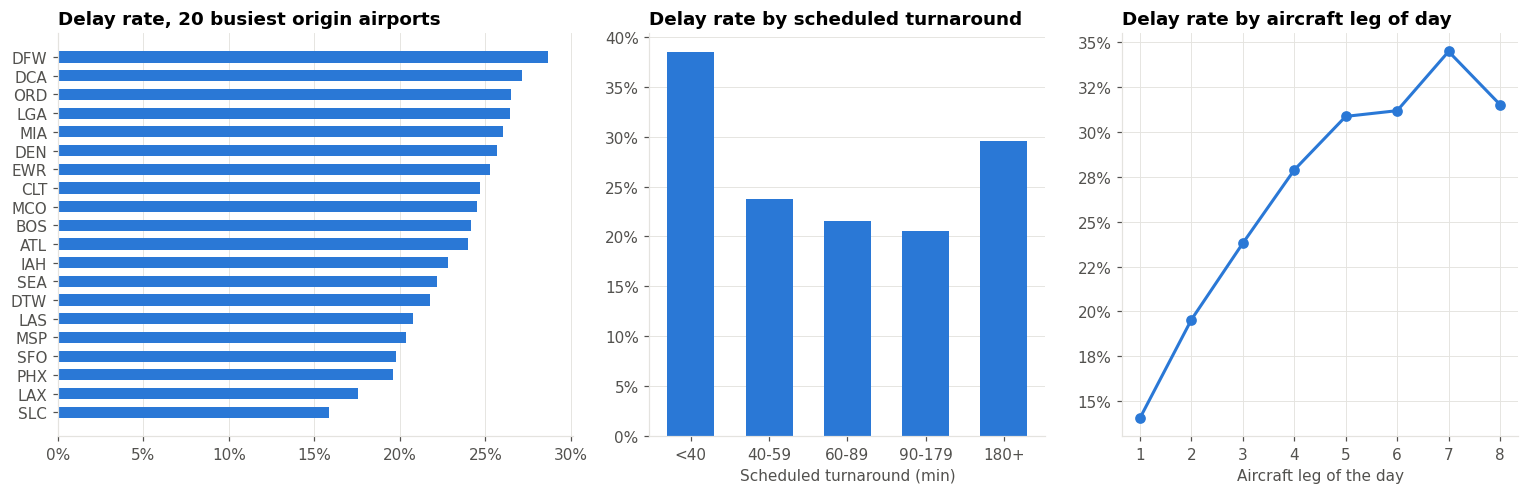

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/04_airport_and_rotation_patterns.png


In [20]:
top_origins = (data.groupBy("ORIGIN").agg(F.count("*").alias("flights"), F.avg("DELAYED").alias("delay_rate"))
               .orderBy(F.desc("flights")).limit(20).toPandas().sort_values("delay_rate"))
top_origins.to_csv(f"{TABLE_DIR}/top20_origin_airports.csv", index=False)

turn = (data.where("HAS_PREV_LEG = 1")
        .withColumn("TURN_BAND", F.when(F.col("SCHED_TURNAROUND_MIN") < 40, "<40")
                    .when(F.col("SCHED_TURNAROUND_MIN") < 60, "40-59")
                    .when(F.col("SCHED_TURNAROUND_MIN") < 90, "60-89")
                    .when(F.col("SCHED_TURNAROUND_MIN") < 180, "90-179").otherwise("180+"))
        .groupBy("TURN_BAND").agg(F.count("*").alias("flights"), F.avg("DELAYED").alias("delay_rate")).toPandas())
turn["order"] = turn["TURN_BAND"].map({"<40": 0, "40-59": 1, "60-89": 2, "90-179": 3, "180+": 4})
turn = turn.sort_values("order")
legs = rate_by("TAIL_LEG_OF_DAY", min_flights=1000)
legs = legs[legs["TAIL_LEG_OF_DAY"] <= 8]
turn.to_csv(f"{TABLE_DIR}/delay_rate_by_turnaround.csv", index=False)
legs.to_csv(f"{TABLE_DIR}/delay_rate_by_leg_of_day.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
ax.barh(top_origins["ORIGIN"], top_origins["delay_rate"], color=NEUTRAL, height=0.6)
ax.set_title("Delay rate, 20 busiest origin airports"); pct_axis(ax, "x"); ax.grid(axis="y", visible=False)
ax = axes[1]
ax.bar(turn["TURN_BAND"], turn["delay_rate"], color=NEUTRAL, width=0.6)
ax.set_xlabel("Scheduled turnaround (min)"); ax.set_title("Delay rate by scheduled turnaround"); pct_axis(ax)
ax.grid(axis="x", visible=False)
ax = axes[2]
ax.plot(legs["TAIL_LEG_OF_DAY"], legs["delay_rate"], marker="o", color=NEUTRAL, markersize=6)
ax.set_xlabel("Aircraft leg of the day"); ax.set_title("Delay rate by aircraft leg of day"); pct_axis(ax)
fig.tight_layout()
save_fig(fig, "04_airport_and_rotation_patterns")

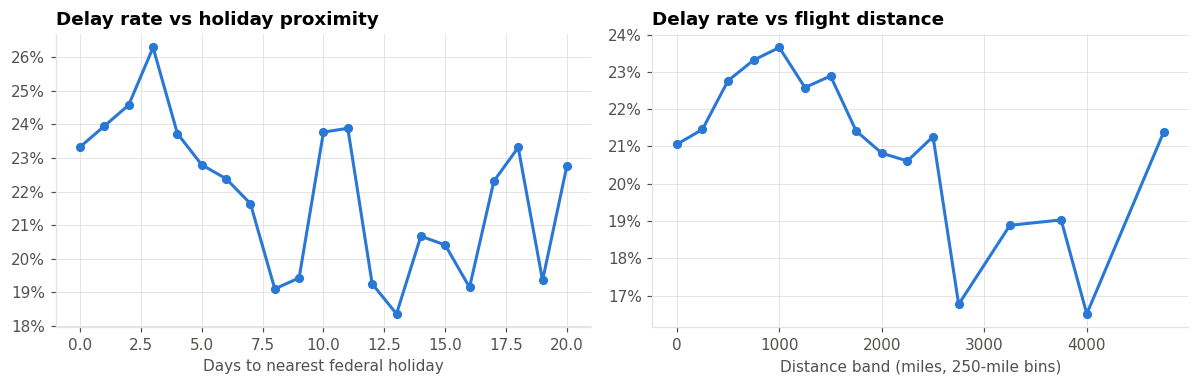

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/05_holiday_and_distance.png


In [21]:
hol_rate = rate_by("DAYS_TO_HOLIDAY")
hol_rate = hol_rate[hol_rate["DAYS_TO_HOLIDAY"] <= 20]
dist = (data.withColumn("DIST_BAND", (F.floor(F.col("DISTANCE") / 250) * 250).cast("int"))
        .groupBy("DIST_BAND").agg(F.count("*").alias("flights"), F.avg("DELAYED").alias("delay_rate"))
        .where("flights >= 1000").orderBy("DIST_BAND").toPandas())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(hol_rate["DAYS_TO_HOLIDAY"], hol_rate["delay_rate"], marker="o", color=NEUTRAL, markersize=5)
axes[0].set_xlabel("Days to nearest federal holiday"); axes[0].set_title("Delay rate vs holiday proximity"); pct_axis(axes[0])
axes[1].plot(dist["DIST_BAND"], dist["delay_rate"], marker="o", color=NEUTRAL, markersize=5)
axes[1].set_xlabel("Distance band (miles, 250-mile bins)"); axes[1].set_title("Delay rate vs flight distance"); pct_axis(axes[1])
fig.tight_layout()
save_fig(fig, "05_holiday_and_distance")

## 9. Train / validation / test split
A random **70 / 10 / 20** split is used.
* **train**: fits the models *and* the target encoders;
* **validation**: picks the decision threshold (never used for fitting);
* **test**: touched once, for the final numbers.

A second, stricter **temporal** evaluation (train on Jan–Sep, test on Oct–Dec) is in Section 14, because a random split lets the model see days from the test period during training.

To keep training feasible on Colab, models are fitted on a `TRAIN_SAMPLE_FRACTION` sample of the training split. Validation and test are always scored in full.

In [22]:
train_full, valid_raw, test_raw = data.randomSplit(SPLIT_WEIGHTS, seed=SEED)
train_raw = train_full.sample(fraction=TRAIN_SAMPLE_FRACTION, seed=SEED) if TRAIN_SAMPLE_FRACTION < 1 else train_full

split_sizes = {name: df.count() for name, df in
               [("train_full", train_full), ("train_used", train_raw), ("validation", valid_raw), ("test", test_raw)]}
pd.Series(split_sizes, name="rows").to_csv(f"{TABLE_DIR}/split_sizes.csv")
for k, v in split_sizes.items():
    print(f"{k:<11} {v:>12,}")

train_full     4,815,461
train_used     1,445,229
validation       687,108
test           1,376,914


## 10. Target encoding of high-cardinality categories (fitted on training data only)
`ORIGIN` (~350 airports), `DEST`, `ROUTE` (~6,000 airport pairs), `ORIGIN_HOUR` and `CARRIER_ORIGIN` are too high-cardinality to one-hot encode efficiently, especially for tree models where `maxBins` would explode. Each one is replaced by its **smoothed historical delay rate**:

$$TE(c) = \frac{n_c \cdot \bar{y}_c + m \cdot \bar{y}}{n_c + m}$$

where $m$ = `TE_SMOOTHING`. Rare categories are pulled towards the global mean $\bar{y}$, which limits over-fitting. The encoders are **computed from the training split only** and then joined (as small broadcast tables) onto validation/test. Unseen categories fall back to $\bar{y}$. Computing them on all data would leak test labels into the features.

In [23]:
TE_COLUMNS = ["ORIGIN", "DEST", "ROUTE", "ORIGIN_HOUR", "CARRIER_ORIGIN"]

def fit_target_encoders(train_df, cols, m=TE_SMOOTHING):
    prior = train_df.agg(F.avg("DELAYED")).first()[0]
    tables = {}
    for c in cols:
        tables[c] = (train_df.groupBy(c).agg(F.count("*").alias("n"), F.avg("DELAYED").alias("mean"))
                     .select(c, ((F.col("n") * F.col("mean") + m * prior) / (F.col("n") + m)).alias(f"TE_{c}"))
                     .cache())
    return prior, tables

def apply_target_encoders(df, prior, tables):
    for c, tbl in tables.items():
        df = df.join(F.broadcast(tbl), c, "left").fillna({f"TE_{c}": prior})
    return df

prior, te_tables = fit_target_encoders(train_full, TE_COLUMNS)
print(f"Training prior delay rate = {prior:.4f}")
for c, tbl in te_tables.items():
    print(f"  TE_{c:<15} {tbl.count():>6} categories")

Training prior delay rate = 0.2231
  TE_ORIGIN             352 categories
  TE_DEST               352 categories
  TE_ROUTE             6886 categories
  TE_ORIGIN_HOUR       4499 categories
  TE_CARRIER_ORIGIN    1639 categories


## 11. Feature assembly pipeline
The final feature vector combines numeric schedule/calendar features, the target-encoded rates and a one-hot encoding of the airline (only ~15 carriers). The same vector feeds all three models so the comparison is fair. It is standardised because Logistic Regression is scale-sensitive; the tree models are unaffected by monotonic rescaling.

**Class imbalance.** Roughly one flight in five is delayed. Each row gets a weight so that both classes contribute equally to the loss: $w_k = N / (2 N_k)$. All three Spark estimators accept `weightCol`.

In [24]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler

NUMERIC_FEATURES = ["MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK", "IS_WEEKEND", "MONTH_SIN", "MONTH_COS",
                    "DEP_HOUR", "ARR_HOUR", "DEP_HOUR_SIN", "DEP_HOUR_COS", "CRS_ELAPSED_TIME", "DISTANCE",
                    "DAYS_TO_HOLIDAY", "ORIGIN_HOURLY_DEPS", "DEST_HOURLY_ARRS", "ORIGIN_DAILY_DEPS",
                    "CARRIER_DAILY_FLIGHTS", "TAIL_LEG_OF_DAY", "SCHED_TURNAROUND_MIN", "HAS_PREV_LEG"]
TE_FEATURES = [f"TE_{c}" for c in TE_COLUMNS]
ASSEMBLED = NUMERIC_FEATURES + TE_FEATURES + ["CARRIER_OHE"]

forbidden = LEAKAGE_COLUMNS.intersection(ASSEMBLED)
assert not forbidden, f"Leakage columns in feature list: {forbidden}"
print(f"{len(NUMERIC_FEATURES)} numeric + {len(TE_FEATURES)} target-encoded + carrier one-hot. Leakage check passed.")

def add_class_weight(df, pos_rate):
    w_pos, w_neg = 0.5 / pos_rate, 0.5 / (1 - pos_rate)
    return df.withColumn("CLASS_WEIGHT", F.when(F.col("DELAYED") == 1, w_pos).otherwise(w_neg)
                         if USE_CLASS_WEIGHTS else F.lit(1.0))

feature_pipeline = Pipeline(stages=[
    StringIndexer(inputCol="REPORTING_AIRLINE", outputCol="CARRIER_IDX", handleInvalid="keep"),
    OneHotEncoder(inputCols=["CARRIER_IDX"], outputCols=["CARRIER_OHE"]),
    VectorAssembler(inputCols=ASSEMBLED, outputCol="features_raw", handleInvalid="keep"),
    StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True),
])

def prepare(df):
    return apply_target_encoders(df, prior, te_tables).fillna(0, subset=NUMERIC_FEATURES)

keep = ["features", "DELAYED", "CLASS_WEIGHT"]
train_enc = add_class_weight(prepare(train_raw), prior)
feature_model = feature_pipeline.fit(train_enc)
train_df = feature_model.transform(train_enc).select(*keep).repartition(N_CORES * 2).cache()
valid_df = feature_model.transform(add_class_weight(prepare(valid_raw), prior)).select(*keep).cache()
test_df  = feature_model.transform(add_class_weight(prepare(test_raw), prior)).select(*keep).cache()
print("train / valid / test cached:", train_df.count(), valid_df.count(), test_df.count())

attrs = feature_model.transform(train_enc.limit(1)).schema["features_raw"].metadata["ml_attr"]["attrs"]
# attrs is grouped by type ("numeric", "binary", ...) and the group order differs between Spark versions,
# so sort ALL attributes by their vector index, not group by group
FEATURE_NAMES = [a["name"] for a in sorted((a for group in attrs.values() for a in group), key=lambda a: a["idx"])]
assert len(FEATURE_NAMES) == len(set(FEATURE_NAMES)) and FEATURE_NAMES[:len(NUMERIC_FEATURES)] == NUMERIC_FEATURES
FEATURE_NAMES = [n.replace("CARRIER_OHE_", "CARRIER=") for n in FEATURE_NAMES]
print(f"Feature vector length: {len(FEATURE_NAMES)}")

20 numeric + 5 target-encoded + carrier one-hot. Leakage check passed.
train / valid / test cached: 1445229 687108 1376914
Feature vector length: 39


## 12. Model training and evaluation helpers
**Why accuracy alone is not enough:** with ~80% on-time flights, a "model" that always says *on time* already reaches ~80% accuracy, yet it never catches a single delay. The **majority-class baseline** is reported next to the real models to make this visible. For the delayed class we report:
* **Precision**: of the flights we flag, how many really were delayed (the cost of false alarms);
* **Recall**: of the delayed flights, how many we caught;
* **F1**: harmonic mean of the two;
* **ROC-AUC**: ranking quality across *all* thresholds (threshold-independent);
* **PR-AUC**: like ROC-AUC but focused on the minority class, so more informative under imbalance;
* **Training time**: wall-clock seconds for `fit()`, since scalability is part of the brief.

All confusion-matrix counts are computed in **one Spark aggregation pass** rather than collecting predictions to the driver.

In [25]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

roc_eval = BinaryClassificationEvaluator(labelCol="DELAYED", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
pr_eval  = BinaryClassificationEvaluator(labelCol="DELAYED", rawPredictionCol="rawPrediction", metricName="areaUnderPR")

def with_prob(pred):
    return pred.withColumn("P_DELAY", vector_to_array("probability")[1])

def confusion_at(pred, threshold):
    yhat = (F.col("P_DELAY") >= threshold).cast("int")
    r = pred.agg(
        F.sum(((yhat == 1) & (F.col("DELAYED") == 1)).cast("long")).alias("TP"),
        F.sum(((yhat == 1) & (F.col("DELAYED") == 0)).cast("long")).alias("FP"),
        F.sum(((yhat == 0) & (F.col("DELAYED") == 0)).cast("long")).alias("TN"),
        F.sum(((yhat == 0) & (F.col("DELAYED") == 1)).cast("long")).alias("FN")).first()
    return {k: int(r[k] or 0) for k in ("TP", "FP", "TN", "FN")}

def metrics_from_cm(cm):
    tp, fp, tn, fn = cm["TP"], cm["FP"], cm["TN"], cm["FN"]
    n = tp + fp + tn + fn
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"accuracy": (tp + tn) / n, "precision": precision, "recall": recall, "f1": f1,
            "specificity": tn / (tn + fp) if tn + fp else 0.0}

def best_threshold(pred, grid=np.round(np.arange(0.05, 0.96, 0.025), 3)):
    """Scan thresholds on the validation set in ONE aggregation and return the F1-maximising one."""
    aggs = []
    for i, t in enumerate(grid):
        yhat = F.col("P_DELAY") >= float(t)
        aggs += [F.sum((yhat & (F.col("DELAYED") == 1)).cast("long")).alias(f"tp{i}"),
                 F.sum((yhat & (F.col("DELAYED") == 0)).cast("long")).alias(f"fp{i}")]
    r = pred.agg(F.sum("DELAYED").alias("P"), *aggs).first()
    rows = []
    for i, t in enumerate(grid):
        tp, fp = r[f"tp{i}"] or 0, r[f"fp{i}"] or 0
        p = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / r["P"] if r["P"] else 0.0
        rows.append({"threshold": float(t), "precision": p, "recall": rec,
                     "f1": 2 * p * rec / (p + rec) if p + rec else 0.0})
    curve = pd.DataFrame(rows)
    return float(curve.loc[curve["f1"].idxmax(), "threshold"]), curve

RESULTS, CURVES, FITTED, CMS = [], {}, {}, {}

def evaluate_model(name, model, train_seconds, stage):
    valid_pred = with_prob(model.transform(valid_df)).cache()
    thr, curve = best_threshold(valid_pred)
    CURVES[name] = curve
    valid_pred.unpersist()

    t0 = time.time()
    test_pred = with_prob(model.transform(test_df)).cache()
    roc_auc, pr_auc = roc_eval.evaluate(test_pred), pr_eval.evaluate(test_pred)
    predict_seconds = time.time() - t0
    for label, t in [("0.50 (default)", 0.5), ("tuned on validation", thr)]:
        cm = confusion_at(test_pred, t)
        CMS[(name, label)] = cm
        RESULTS.append({"model": name, "stage": stage, "threshold_rule": label, "threshold": round(t, 3),
                        **metrics_from_cm(cm), "roc_auc": roc_auc, "pr_auc": pr_auc,
                        "train_seconds": train_seconds, "score_seconds": predict_seconds, **cm})
    pd.DataFrame(RESULTS).to_csv(f"{TABLE_DIR}/model_results_all.csv", index=False)   # checkpoint
    return test_pred

def fit_timed(estimator):
    t0 = time.time()
    model = estimator.fit(train_df)
    return model, time.time() - t0

# Majority-class baseline: always predicts "on time"
cm_base = test_df.agg(F.sum(1 - F.col("DELAYED")).alias("TN"), F.sum("DELAYED").alias("FN")).first()
cm_base = {"TP": 0, "FP": 0, "TN": int(cm_base["TN"]), "FN": int(cm_base["FN"])}
RESULTS.append({"model": "Majority baseline", "stage": "baseline", "threshold_rule": "n/a", "threshold": None,
                **metrics_from_cm(cm_base), "roc_auc": 0.5, "pr_auc": None, "train_seconds": 0.0,
                "score_seconds": 0.0, **cm_base})
print("Majority baseline:", {k: round(v, 4) for k, v in metrics_from_cm(cm_base).items()})

Majority baseline: {'accuracy': 0.777, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'specificity': 1.0}


## 13. Model 1, 2, 3: baseline configurations
Sensible, commonly used starting configurations. Section 13.4 then tunes them with cross-validation.

In [26]:
ESTIMATORS = {
    "Logistic Regression": LogisticRegression(featuresCol="features", labelCol="DELAYED", weightCol="CLASS_WEIGHT",
                                              maxIter=100, regParam=0.001, elasticNetParam=0.0),
    "Random Forest": RandomForestClassifier(featuresCol="features", labelCol="DELAYED", weightCol="CLASS_WEIGHT",
                                            numTrees=100, maxDepth=10, maxBins=64, subsamplingRate=0.8,
                                            featureSubsetStrategy="sqrt", seed=SEED),
    "Gradient-Boosted Trees": GBTClassifier(featuresCol="features", labelCol="DELAYED", weightCol="CLASS_WEIGHT",
                                            maxIter=60, maxDepth=6, stepSize=0.1, maxBins=64, subsamplingRate=0.8,
                                            seed=SEED),
}

### 13.1 Logistic Regression
A linear, well-understood baseline: fast, scales almost linearly with data, and its coefficients are directly interpretable. It can only model straight-line relationships in the (standardised) features, which is why the cyclical and target-encoded features matter for it.

In [27]:
name = "Logistic Regression"
if RUN_BASELINE_MODELS:
    model, secs = fit_timed(ESTIMATORS[name])
    FITTED[name] = model
    evaluate_model(name, model, secs, "baseline")
    print(f"{name}: trained in {secs:.1f} s, iterations = {model.summary.totalIterations}")
    display(pd.DataFrame(RESULTS).query("model == @name"))
else:
    print("RUN_BASELINE_MODELS is False, so the default configuration is skipped (tuned model is fitted in 13.4).")

Logistic Regression: trained in 48.8 s, iterations = 51


,model,stage,threshold_rule,threshold,accuracy,precision,recall,f1,specificity,roc_auc,pr_auc,train_seconds,score_seconds,TP,FP,TN,FN
1,Logistic Regression,baseline,0.50 (default),0.5,0.623557,0.324863,0.638121,0.430541,0.619377,0.676109,0.367391,48.79913,71.092988,195942,407211,662642,111119
2,Logistic Regression,baseline,tuned on validation,0.5,0.623557,0.324863,0.638121,0.430541,0.619377,0.676109,0.367391,48.79913,71.092988,195942,407211,662642,111119


### 13.2 Random Forest
An ensemble of decorrelated decision trees trained in parallel on bootstrap samples. It captures non-linear effects and interactions (e.g. *evening* + *tight turnaround*), and each tree can be built independently, which suits Spark's data-parallel design.

In [28]:
name = "Random Forest"
if RUN_BASELINE_MODELS:
    model, secs = fit_timed(ESTIMATORS[name])
    FITTED[name] = model
    evaluate_model(name, model, secs, "baseline")
    print(f"{name}: trained in {secs:.1f} s")
    display(pd.DataFrame(RESULTS).query("model == @name"))
else:
    print("RUN_BASELINE_MODELS is False, so the default configuration is skipped (tuned model is fitted in 13.4).")

Random Forest: trained in 1077.0 s


,model,stage,threshold_rule,threshold,accuracy,precision,recall,f1,specificity,roc_auc,pr_auc,train_seconds,score_seconds,TP,FP,TN,FN
3,Random Forest,baseline,0.50 (default),0.5,0.650596,0.346632,0.640505,0.449825,0.653493,0.705037,0.4436,1077.010715,113.656655,196674,370712,699141,110387
4,Random Forest,baseline,tuned on validation,0.5,0.650596,0.346632,0.640505,0.449825,0.653493,0.705037,0.4436,1077.010715,113.656655,196674,370712,699141,110387


### 13.3 Gradient-Boosted Trees
Trees are added sequentially, each correcting the errors of the previous ensemble. GBTs usually give the best accuracy on tabular data, but the boosting rounds are inherently sequential (only the work *within* each tree is parallelised), so training is slower.

In [29]:
name = "Gradient-Boosted Trees"
if RUN_BASELINE_MODELS:
    model, secs = fit_timed(ESTIMATORS[name])
    FITTED[name] = model
    evaluate_model(name, model, secs, "baseline")
    print(f"{name}: trained in {secs:.1f} s")
    display(pd.DataFrame(RESULTS).query("model == @name"))
else:
    print("RUN_BASELINE_MODELS is False, so the default configuration is skipped (tuned model is fitted in 13.4).")

Gradient-Boosted Trees: trained in 442.9 s


,model,stage,threshold_rule,threshold,accuracy,precision,recall,f1,specificity,roc_auc,pr_auc,train_seconds,score_seconds,TP,FP,TN,FN
5,Gradient-Boosted Trees,baseline,0.50 (default),0.500,0.688425,0.381855,0.641824,0.478829,0.701800,0.73515,0.482435,442.869764,67.785241,197079,319030,750823,109982
6,Gradient-Boosted Trees,baseline,tuned on validation,0.525,0.710251,0.399912,0.597904,0.479264,0.742496,0.73515,0.482435,442.869764,67.785241,183593,275491,794362,123468


### 13.4 Hyperparameter tuning with k-fold cross-validation
`CrossValidator` runs a small grid per model with `CV_FOLDS`-fold cross-validation on a stratified-by-chance random sample of the training data (`TUNING_SAMPLE_FRACTION`), optimising **PR-AUC** (better suited than ROC-AUC to an imbalanced target). Models are evaluated in parallel (`parallelism`). The best parameters are then refitted on the full training sample and evaluated on the test set exactly like the baselines.

Grids are intentionally small so the notebook finishes on free Colab; they can be widened on a cluster.

In [30]:
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

MODELS = ["Logistic Regression", "Random Forest", "Gradient-Boosted Trees"]
TUNED_PARAMS, CV_SCORES = {}, {}

def fit_tuned(name, params):
    est = ESTIMATORS[name].copy({ESTIMATORS[name].getParam(k): v for k, v in params.items()})
    model, secs = fit_timed(est)
    FITTED[name + " (tuned)"] = model
    evaluate_model(name, model, secs, "tuned")
    print(f"{name} (tuned {params}): trained in {secs:.1f} s")

if TUNED_PARAMS_OVERRIDE:
    print("Using tuned parameters from an earlier CrossValidator run (TUNED_PARAMS_OVERRIDE).")
    TUNED_PARAMS = dict(TUNED_PARAMS_OVERRIDE)
    CV_SCORES = dict(CV_SCORES_OVERRIDE or {})
    for name in MODELS:
        if name in TUNED_PARAMS:
            fit_tuned(name, TUNED_PARAMS[name])
elif RUN_TUNING:
    tune_df = train_df.sample(fraction=min(1.0, TUNING_SAMPLE_FRACTION / max(TRAIN_SAMPLE_FRACTION, 1e-9)),
                              seed=SEED).cache()
    print(f"Tuning sample: {tune_df.count():,} rows")
    lr, rf, gbt = (ESTIMATORS[k] for k in ["Logistic Regression", "Random Forest", "Gradient-Boosted Trees"])
    grids = {
        "Logistic Regression": ParamGridBuilder()
            .addGrid(lr.regParam, [0.0001, 0.001, 0.01])
            .addGrid(lr.elasticNetParam, [0.0, 0.5]).build(),
        "Random Forest": ParamGridBuilder()
            .addGrid(rf.maxDepth, [8, 12])
            .addGrid(rf.numTrees, [60, 120]).build(),
        "Gradient-Boosted Trees": ParamGridBuilder()
            .addGrid(gbt.maxDepth, [4, 6])
            .addGrid(gbt.stepSize, [0.05, 0.1]).build(),
    }
    cv_rows = []
    for name, grid in grids.items():
        cv = CrossValidator(estimator=ESTIMATORS[name], estimatorParamMaps=grid, evaluator=pr_eval,
                            numFolds=CV_FOLDS, parallelism=min(4, N_CORES), seed=SEED)
        t0 = time.time()
        cv_model = cv.fit(tune_df)
        cv_secs = time.time() - t0
        best_i = int(np.argmax(cv_model.avgMetrics))
        TUNED_PARAMS[name] = {p.name: v for p, v in grid[best_i].items()}
        for pm, score in zip(grid, cv_model.avgMetrics):
            cv_rows.append({"model": name, "params": json.dumps({p.name: v for p, v in pm.items()}),
                            "cv_pr_auc": score, "best": pm == grid[best_i]})
        CV_SCORES[name] = float(cv_model.avgMetrics[best_i])
        print(f"{name}: best {TUNED_PARAMS[name]}  (CV PR-AUC {CV_SCORES[name]:.4f}, {cv_secs:.0f} s)")
        pd.DataFrame(cv_rows).to_csv(f"{TABLE_DIR}/cross_validation_grid.csv", index=False)   # checkpoint
        fit_tuned(name, TUNED_PARAMS[name])
    tune_df.unpersist()
else:
    print("RUN_TUNING is False, so tuning is skipped.")

# safety net: every model must exist in some form before the comparison
for name in MODELS:
    if name not in FITTED and name + " (tuned)" not in FITTED:
        print(f"{name}: no fitted model yet, fitting the default configuration.")
        model, secs = fit_timed(ESTIMATORS[name])
        FITTED[name] = model
        evaluate_model(name, model, secs, "baseline")

Tuning sample: 241,231 rows
Logistic Regression: best {'regParam': 0.0001, 'elasticNetParam': 0.0}  (CV PR-AUC 0.3693, 267 s)
Logistic Regression (tuned {'regParam': 0.0001, 'elasticNetParam': 0.0}): trained in 47.0 s
Random Forest: best {'maxDepth': 12, 'numTrees': 120}  (CV PR-AUC 0.4441, 2246 s)
Random Forest (tuned {'maxDepth': 12, 'numTrees': 120}): trained in 2115.4 s
Gradient-Boosted Trees: best {'maxDepth': 6, 'stepSize': 0.1}  (CV PR-AUC 0.4687, 1107 s)
Gradient-Boosted Trees (tuned {'maxDepth': 6, 'stepSize': 0.1}): trained in 464.7 s


## 14. Model comparison

In [31]:
results = pd.DataFrame(RESULTS)
results.to_csv(f"{TABLE_DIR}/model_results_all.csv", index=False)

# The headline table: per model, the best stage (tuned if available) at the validation-tuned threshold
headline = (results[results["threshold_rule"] != "0.50 (default)"]
            .sort_values("stage", key=lambda s: s.map({"baseline": 1, "tuned": 0}))
            .drop_duplicates("model"))
headline = headline.set_index("model").loc[["Majority baseline", "Logistic Regression", "Random Forest", "Gradient-Boosted Trees"]]
cols = ["stage", "threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "train_seconds"]
headline[cols].to_csv(f"{TABLE_DIR}/model_results_headline.csv")
print(headline[cols].round(4).to_string())

def final_model(name):
    return FITTED[name + " (tuned)"] if name + " (tuned)" in FITTED else FITTED[name]

                           stage  threshold  accuracy  precision  recall      f1  roc_auc  pr_auc  train_seconds
model                                                                                                           
Majority baseline       baseline        NaN    0.7770     0.0000  0.0000  0.0000   0.5000     NaN         0.0000
Logistic Regression        tuned      0.500    0.6239     0.3251  0.6381  0.4308   0.6765  0.3680        47.0254
Random Forest              tuned      0.500    0.6694     0.3616  0.6304  0.4596   0.7150  0.4567      2115.3711
Gradient-Boosted Trees     tuned      0.525    0.7103     0.3999  0.5979  0.4793   0.7351  0.4824       464.7477


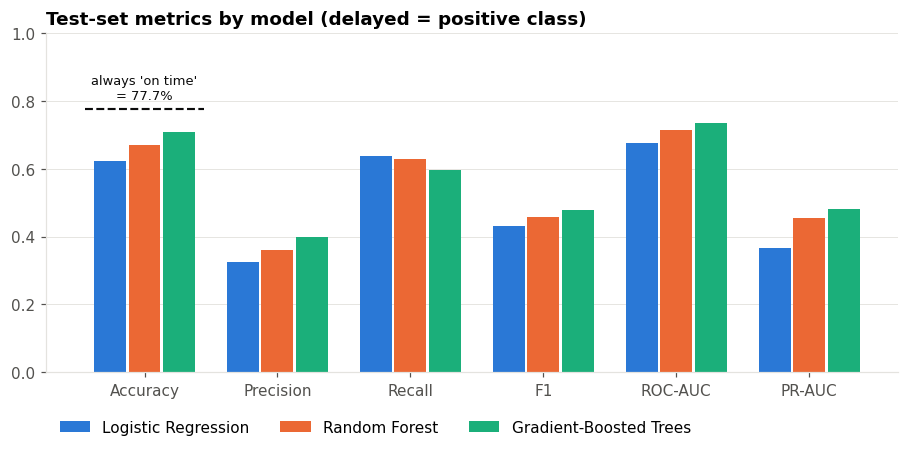

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/06_model_metrics.png


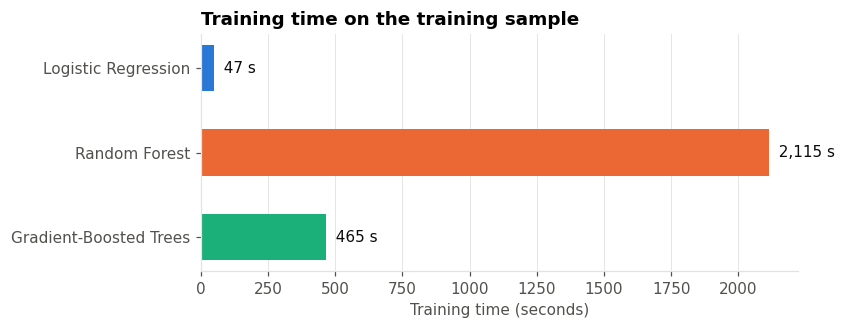

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/07_training_time.png


In [32]:
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(metric_names)); width = 0.26
for i, m in enumerate(MODELS):
    vals = headline.loc[m, metric_names].astype(float).values
    ax.bar(x + (i - 1) * width, vals, width - 0.02, label=m, color=MODEL_COLORS[m])
base_acc = headline.loc["Majority baseline", "accuracy"]
ax.hlines(base_acc, -0.45, 0.45, color=INK, linestyle="--", linewidth=1.4)
ax.text(0, base_acc + 0.02, f"always 'on time'\n= {base_acc:.1%}", ha="center", va="bottom", fontsize=8.5, color=INK)
ax.set_xticks(x, ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"])
ax.set_ylim(0, 1); ax.set_title("Test-set metrics by model (delayed = positive class)")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.1)); ax.grid(axis="x", visible=False)
save_fig(fig, "06_model_metrics")

fig, ax = plt.subplots(figsize=(7, 2.8))
secs = headline.loc[MODELS, "train_seconds"].astype(float)
bars = ax.barh(MODELS[::-1], secs[::-1], color=[MODEL_COLORS[m] for m in MODELS[::-1]], height=0.55)
for b, s in zip(bars, secs[::-1]):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {s:,.0f} s", va="center", color=INK)
ax.set_xlabel("Training time (seconds)"); ax.set_title("Training time on the training sample")
ax.grid(axis="y", visible=False)
save_fig(fig, "07_training_time")

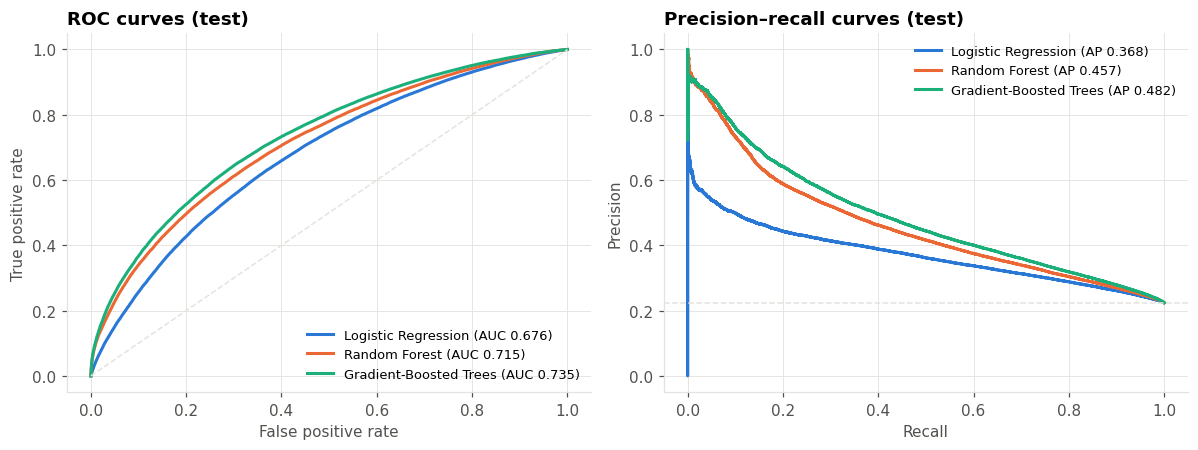

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/08_roc_pr_curves.png


DataFrame[features: vector, DELAYED: int, CLASS_WEIGHT: double]

In [33]:
from sklearn.metrics import roc_curve, precision_recall_curve

PLOT_SAMPLE = 300_000
frac = min(1.0, PLOT_SAMPLE / split_sizes["test"])
test_sample = test_df.sample(fraction=frac, seed=SEED).cache()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for m in MODELS:
    pdf = with_prob(final_model(m).transform(test_sample)).select("DELAYED", "P_DELAY").toPandas()
    fpr, tpr, _ = roc_curve(pdf["DELAYED"], pdf["P_DELAY"])
    prec, rec, _ = precision_recall_curve(pdf["DELAYED"], pdf["P_DELAY"])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[m], label=f"{m} (AUC {headline.loc[m, 'roc_auc']:.3f})")
    axes[1].plot(rec, prec, color=MODEL_COLORS[m], label=f"{m} (AP {headline.loc[m, 'pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=GRID, linestyle="--", linewidth=1)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curves (test)")
axes[1].axhline(POS_RATE, color=GRID, linestyle="--", linewidth=1)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision–recall curves (test)")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=8.5)
fig.tight_layout()
save_fig(fig, "08_roc_pr_curves")
test_sample.unpersist()

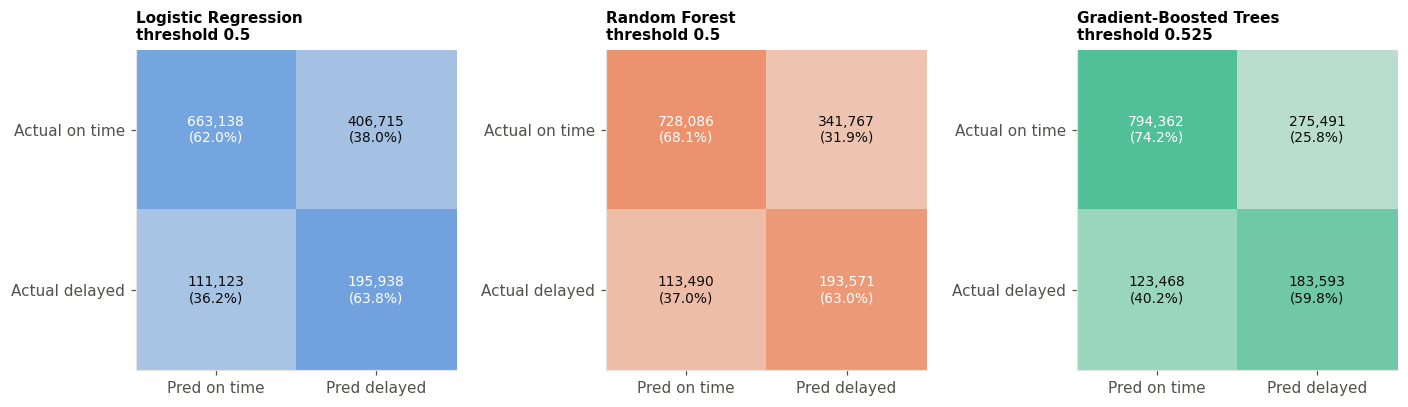

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/09_confusion_matrices.png


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, m in zip(axes, MODELS):
    # final (tuned if available) model = the last matrix recorded for this model at the validation threshold
    cm = [r for r in RESULTS if r["model"] == m and r["threshold_rule"] == "tuned on validation"][-1]
    mat = np.array([[cm["TN"], cm["FP"]], [cm["FN"], cm["TP"]]])
    norm = mat / mat.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap=matplotlib.colors.LinearSegmentedColormap.from_list("b", ["#f0efec", MODEL_COLORS[m]]),
              vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(mat):
        ax.text(j, i, f"{v:,}\n({norm[i, j]:.1%})", ha="center", va="center",
                color="white" if norm[i, j] > 0.6 else INK, fontsize=9)
    ax.set_xticks([0, 1], ["Pred on time", "Pred delayed"]); ax.set_yticks([0, 1], ["Actual on time", "Actual delayed"])
    ax.set_title(f"{m}\nthreshold {cm['threshold']}", fontsize=10); ax.grid(False)
fig.tight_layout()
save_fig(fig, "09_confusion_matrices")

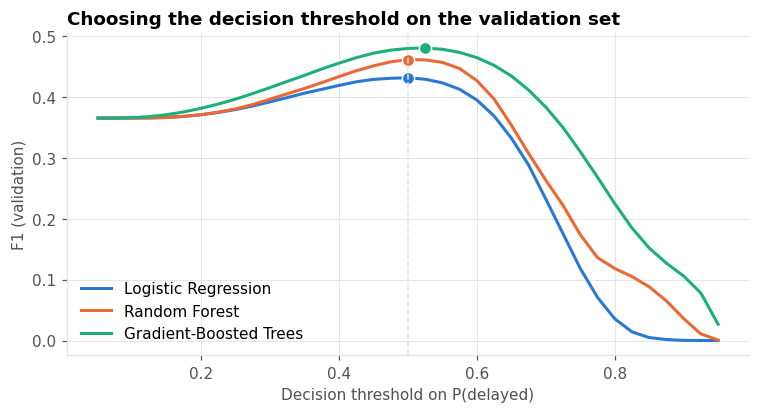

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/10_threshold_tuning.png


In [35]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for m in MODELS:
    c = CURVES[m]
    ax.plot(c["threshold"], c["f1"], color=MODEL_COLORS[m], label=m)
    best = c.loc[c["f1"].idxmax()]
    ax.plot(best["threshold"], best["f1"], "o", color=MODEL_COLORS[m], markersize=8, markeredgecolor="white")
ax.axvline(0.5, color=GRID, linestyle="--", linewidth=1)
ax.set_xlabel("Decision threshold on P(delayed)"); ax.set_ylabel("F1 (validation)")
ax.set_title("Choosing the decision threshold on the validation set"); ax.legend()
save_fig(fig, "10_threshold_tuning")
pd.concat({m: CURVES[m] for m in CURVES}).to_csv(f"{TABLE_DIR}/threshold_curves.csv")

## 15. Model interpretation and feature importance
* **Random Forest / GBT:** impurity-based `featureImportances` (how much each feature reduces impurity across all splits, normalised to sum to 1).
* **Logistic Regression:** coefficients on standardised features. The sign gives the direction and the size gives the strength *per one standard deviation*.

Impurity importance is known to favour continuous, high-cardinality features, so a model-agnostic **permutation importance** on a test sample (for GBT) is added as a robustness check.

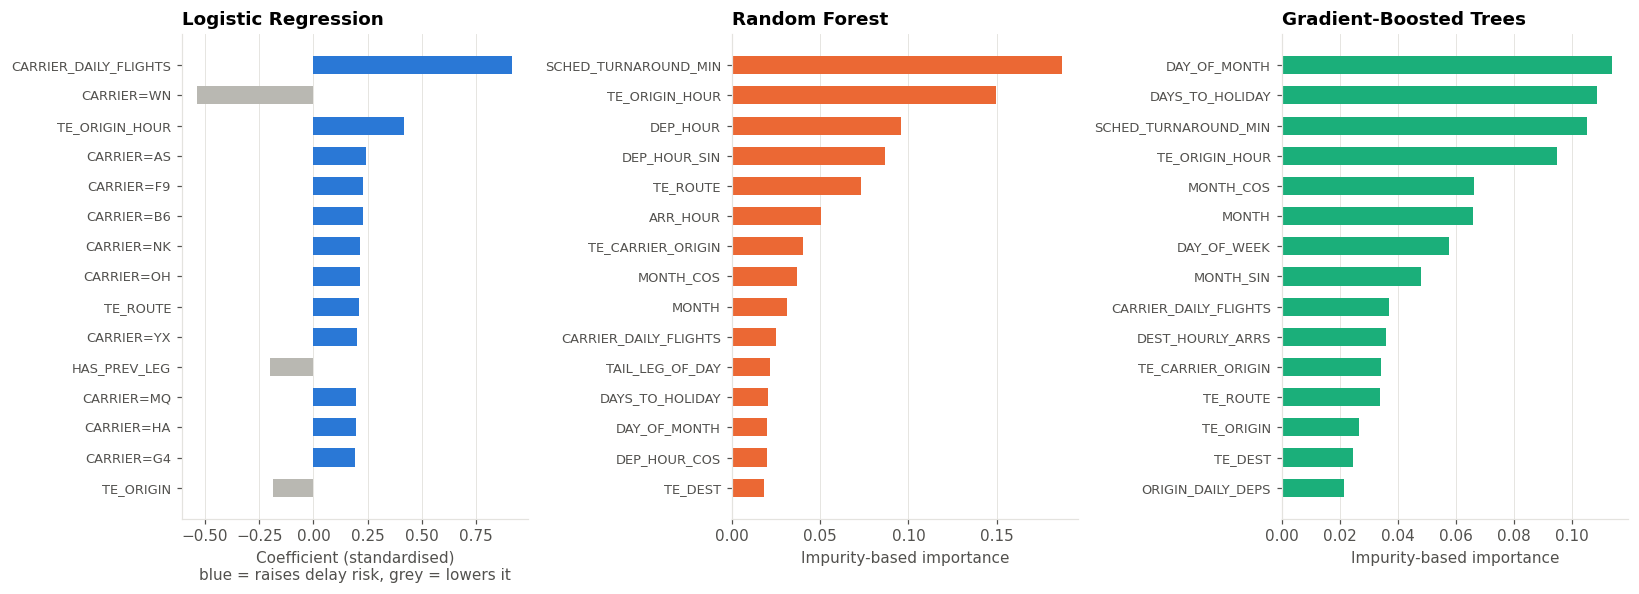

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/11_feature_importance.png


In [36]:
imp_frames = []
for m in ["Random Forest", "Gradient-Boosted Trees"]:
    imp = final_model(m).featureImportances.toArray()
    imp_frames.append(pd.DataFrame({"model": m, "feature": FEATURE_NAMES, "importance": imp}))
lr_coef = final_model("Logistic Regression").coefficients.toArray()
imp_frames.append(pd.DataFrame({"model": "Logistic Regression", "feature": FEATURE_NAMES, "importance": lr_coef}))
importances = pd.concat(imp_frames)
importances.to_csv(f"{TABLE_DIR}/feature_importance.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, m in zip(axes, MODELS):
    t = importances[importances.model == m].copy()
    t["abs"] = t["importance"].abs()
    t = t.sort_values("abs").tail(15)
    if m == "Logistic Regression":
        colors = [MODEL_COLORS[m] if v > 0 else "#b9b8b2" for v in t["importance"]]
        ax.set_xlabel("Coefficient (standardised)\nblue = raises delay risk, grey = lowers it")
    else:
        colors = MODEL_COLORS[m]
        ax.set_xlabel("Impurity-based importance")
    ax.barh(t["feature"], t["importance"], color=colors, height=0.6)
    ax.set_title(m); ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8.5)
fig.tight_layout()
save_fig(fig, "11_feature_importance")

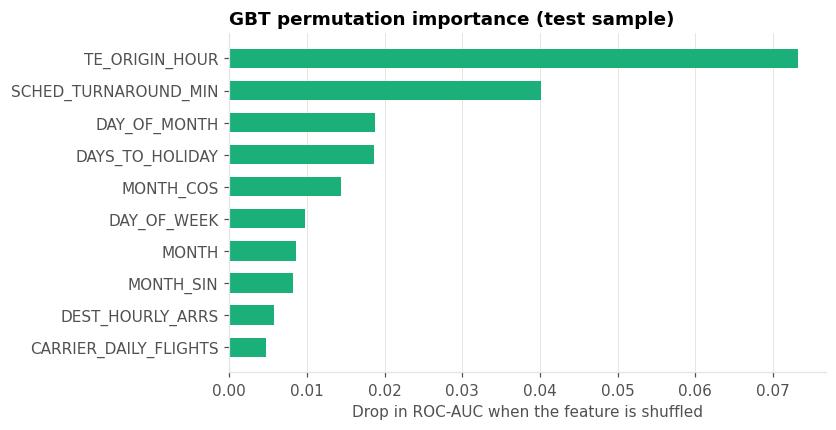

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/12_gbt_permutation_importance.png


In [37]:
# Permutation importance for GBT on a test sample (model-agnostic check). Shuffles one raw feature at a time.
PERM_SAMPLE = 100_000
perm_base = test_df.sample(fraction=min(1.0, PERM_SAMPLE / split_sizes["test"]), seed=SEED).toPandas()
X = np.vstack(perm_base["features"].apply(lambda v: v.toArray()).values)
y = perm_base["DELAYED"].values
gbt_final = final_model("Gradient-Boosted Trees")

from pyspark.ml.linalg import Vectors
from sklearn.metrics import roc_auc_score

def auc_on(Xm):
    sdf = spark.createDataFrame([(Vectors.dense(r),) for r in Xm], ["features"])
    p = gbt_final.transform(sdf).select(vector_to_array("probability")[1].alias("p")).toPandas()["p"].values
    return roc_auc_score(y, p)

rng = np.random.default_rng(SEED)
base_auc = auc_on(X)
top_feats = (importances[importances.model == "Gradient-Boosted Trees"].sort_values("importance", ascending=False)
             .head(10)["feature"].tolist())
perm_rows = []
for fname in top_feats:
    j = FEATURE_NAMES.index(fname)
    Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
    perm_rows.append({"feature": fname, "auc_drop": base_auc - auc_on(Xp)})
perm = pd.DataFrame(perm_rows).sort_values("auc_drop")
perm.to_csv(f"{TABLE_DIR}/gbt_permutation_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(perm["feature"], perm["auc_drop"], color=MODEL_COLORS["Gradient-Boosted Trees"], height=0.6)
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title("GBT permutation importance (test sample)"); ax.grid(axis="y", visible=False)
save_fig(fig, "12_gbt_permutation_importance")

## 16. Export results and models

In [38]:
summary = {
    "generated_at": dt.datetime.now().isoformat(timespec="seconds"),
    "spark_version": spark.version, "cores": N_CORES, "driver_memory_gb": DRIVER_MEM_GB,
    "rows_raw": int(n_raw), "rows_clean": int(n_clean), "positive_rate": POS_RATE,
    "split_sizes": split_sizes, "train_sample_fraction": TRAIN_SAMPLE_FRACTION,
    "features": FEATURE_NAMES, "tuned_params": TUNED_PARAMS,
    "csv_vs_parquet_seconds": {"csv": csv_s, "parquet": parquet_s},
    "headline": headline[cols].reset_index().to_dict(orient="records"),
}
with open(f"{OUTPUT_DIR}/run_summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=str)

if SAVE_MODELS:
    feature_model.write().overwrite().save(f"{MODEL_DIR}/feature_pipeline")
    for m in MODELS:
        final_model(m).write().overwrite().save(f"{MODEL_DIR}/{m.replace(' ', '_').replace('-', '_').lower()}")

shutil.make_archive(f"{LOCAL_WORK}/bdmla_outputs", "zip", OUTPUT_DIR, ".")
print("Outputs folder :", OUTPUT_DIR)
for p in sorted(glob.glob(f"{OUTPUT_DIR}/**/*", recursive=True)):
    if os.path.isfile(p) and "/models/" not in p and "staged_2025" not in p:
        print("  ", os.path.relpath(p, OUTPUT_DIR))

Outputs folder : /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs
   figures/01_class_balance.png
   figures/02_cleaning_funnel.png
   figures/03_delay_rate_patterns.png
   figures/04_airport_and_rotation_patterns.png
   figures/05_holiday_and_distance.png
   figures/06_model_metrics.png
   figures/07_training_time.png
   figures/08_roc_pr_curves.png
   figures/09_confusion_matrices.png
   figures/10_threshold_tuning.png
   figures/11_feature_importance.png
   figures/12_gbt_permutation_importance.png
   report_placeholders.json
   run_summary.json
   tables/class_balance.csv
   tables/cleaning_funnel.csv
   tables/cross_validation_grid.csv
   tables/csv_vs_parquet_benchmark.csv
   tables/delay_rate_by_carrier.csv
   tables/delay_rate_by_day_of_week.csv
   tables/delay_rate_by_dep_hour.csv
   tables/delay_rate_by_leg_of_day.csv
   tables/delay_rate_by_month.csv
   tables/delay_rate_by_turnaround.csv
   tables/feature_importance.csv
   tables/gbt_permutation_importance.csv
   tables

### 16.1 Numbers to copy into the report
This cell prints every value the report template asks for, keyed by its placeholder name (e.g. `[RAW_ROWS]`).

In [39]:
def fmt_pct(v): return f"{v:.2%}"
ph = {
    "RAW_ROWS": f"{n_raw:,}", "CLEAN_ROWS": f"{n_clean:,}", "DELAY_RATE": fmt_pct(POS_RATE),
    "CANCELLED_ROWS": f"{status['cancelled']:,}", "DIVERTED_ROWS": f"{status['diverted']:,}",
    "TRAIN_ROWS_USED": f"{split_sizes['train_used']:,}", "TEST_ROWS": f"{split_sizes['test']:,}",
    "CSV_SECONDS": f"{csv_s:.1f}", "PARQUET_SECONDS": f"{parquet_s:.1f}", "PARQUET_SPEEDUP": f"{csv_s / parquet_s:.1f}x",
    "BASELINE_ACCURACY": fmt_pct(headline.loc["Majority baseline", "accuracy"]),
}
short = {"Logistic Regression": "LR", "Random Forest": "RF", "Gradient-Boosted Trees": "GBT"}
for m in MODELS:
    for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]:
        ph[f"{short[m]}_{k.upper()}"] = f"{float(headline.loc[m, k]):.3f}"
    ph[f"{short[m]}_TRAIN_S"] = f"{float(headline.loc[m, 'train_seconds']):.0f}"
    ph[f"{short[m]}_THRESHOLD"] = f"{float(headline.loc[m, 'threshold']):.3f}"
for i, r in funnel_df.reset_index(drop=True).iterrows():
    ph[f"FUNNEL_{i}_ROWS"] = f"{int(r['rows']):,}"
    ph[f"FUNNEL_{i}_REMOVED"] = f"{int(r['removed']):,}"
ph["N_CORES"] = str(N_CORES)
ph["SPARK_VERSION"] = spark.version
ph["TRAIN_SAMPLE_PCT"] = f"{TRAIN_SAMPLE_FRACTION:.0%}"
ph["VALID_ROWS"] = f"{split_sizes['validation']:,}"
ph["N_FEATURES"] = str(len(FEATURE_NAMES))
hm = headline.loc[MODELS].astype({"f1": float, "roc_auc": float, "pr_auc": float, "train_seconds": float})
ph["BEST_F1_MODEL"]  = hm["f1"].idxmax()
ph["BEST_F1_VALUE"]  = f"{hm['f1'].max():.3f}"
ph["BEST_AUC_MODEL"] = hm["roc_auc"].idxmax()
ph["FASTEST_MODEL"]  = hm["train_seconds"].idxmin()
ph["SLOWEST_MODEL"]  = hm["train_seconds"].idxmax()
gbt_top = (importances[importances.model == "Gradient-Boosted Trees"].sort_values("importance", ascending=False)["feature"]
           .head(5).tolist())
for i, fname in enumerate(gbt_top, 1):
    ph[f"GBT_TOP_FEATURE_{i}"] = fname
for m in MODELS:
    ph[f"{short[m]}_TUNED_PARAMS"] = ", ".join(f"{k}={v}" for k, v in TUNED_PARAMS.get(m, {}).items()) or "not tuned"
    ph[f"{short[m]}_CV_PR_AUC"] = f"{CV_SCORES[m]:.3f}" if m in CV_SCORES else "n/a"
for k, v in ph.items():
    print(f"[{k}]".ljust(24), v)
with open(f"{OUTPUT_DIR}/report_placeholders.json", "w") as fh:
    json.dump(ph, fh, indent=2)

[RAW_ROWS]               7,001,619
[CLEAN_ROWS]             6,879,483
[DELAY_RATE]             22.31%
[CANCELLED_ROWS]         102,876
[DIVERTED_ROWS]          19,258
[TRAIN_ROWS_USED]        1,445,229
[TEST_ROWS]              1,376,914
[CSV_SECONDS]            79.8
[PARQUET_SECONDS]        3.2
[PARQUET_SPEEDUP]        25.1x
[BASELINE_ACCURACY]      77.70%
[LR_ACCURACY]            0.624
[LR_PRECISION]           0.325
[LR_RECALL]              0.638
[LR_F1]                  0.431
[LR_ROC_AUC]             0.676
[LR_PR_AUC]              0.368
[LR_TRAIN_S]             47
[LR_THRESHOLD]           0.500
[RF_ACCURACY]            0.669
[RF_PRECISION]           0.362
[RF_RECALL]              0.630
[RF_F1]                  0.460
[RF_ROC_AUC]             0.715
[RF_PR_AUC]              0.457
[RF_TRAIN_S]             2115
[RF_THRESHOLD]           0.500
[GBT_ACCURACY]           0.710
[GBT_PRECISION]          0.400
[GBT_RECALL]             0.598
[GBT_F1]                 0.479
[GBT_ROC_AUC]            

## 17. Temporal hold-out: train Jan–Sep, test Oct–Dec
Runs after the export so the main results are already saved if Colab disconnects here. A random split lets the model learn from days that are in the test set (the same storm, the same holiday week). In production, the model would always predict the *future*. Here the whole feature pipeline (target encoders included) is refitted on January–September only and evaluated on October–December. A drop compared with the random split tells us how much of the performance was "seen-it-before" knowledge.

                       random split                                           temporal split                                          
                           accuracy precision  recall      f1 roc_auc  pr_auc       accuracy precision  recall      f1 roc_auc  pr_auc
model                                                                                                                                 
Logistic Regression          0.6239    0.3251  0.6381  0.4308  0.6765  0.3680         0.7626    0.3726  0.0785  0.1297  0.6034  0.2974
Random Forest                0.6694    0.3616  0.6304  0.4596  0.7150  0.4567         0.6986    0.3634  0.4492  0.4018  0.6724  0.4012
Gradient-Boosted Trees       0.7103    0.3999  0.5979  0.4793  0.7351  0.4824         0.7431    0.4155  0.3447  0.3768  0.6790  0.4131


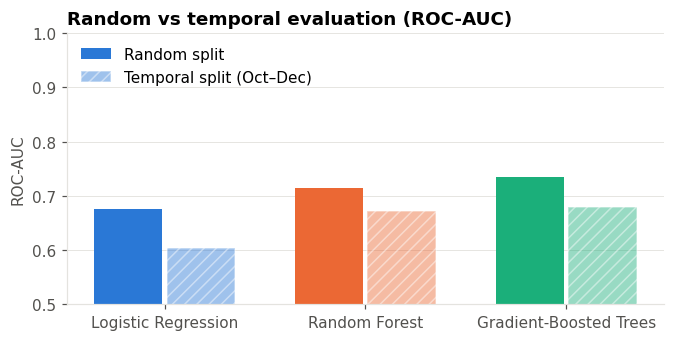

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/13_random_vs_temporal.png
Temporal results added to report_placeholders.json


In [40]:
if RUN_TEMPORAL_HOLDOUT:
    t_train_all = data.where(F.col("MONTH") <= 9)
    t_test_raw  = data.where(F.col("MONTH") >= 10)
    t_train_raw = t_train_all.sample(fraction=TRAIN_SAMPLE_FRACTION, seed=SEED) if TRAIN_SAMPLE_FRACTION < 1 else t_train_all

    t_prior, t_tables = fit_target_encoders(t_train_all, TE_COLUMNS)
    t_prep = lambda df: apply_target_encoders(df, t_prior, t_tables).fillna(0, subset=NUMERIC_FEATURES)
    t_train_enc = add_class_weight(t_prep(t_train_raw), t_prior)
    t_feat = feature_pipeline.fit(t_train_enc)
    t_train = t_feat.transform(t_train_enc).select(*keep).cache()
    t_test  = t_feat.transform(add_class_weight(t_prep(t_test_raw), t_prior)).select(*keep).cache()

    temporal_rows = []
    for m in MODELS:
        est = ESTIMATORS[m].copy()
        if m in TUNED_PARAMS:
            est = est.copy({est.getParam(k): v for k, v in TUNED_PARAMS[m].items()})
        t0 = time.time(); tm = est.fit(t_train); secs = time.time() - t0
        tp = with_prob(tm.transform(t_test)).cache()
        thr = headline.loc[m, "threshold"]
        row = {"model": m, "split": "temporal (train Jan–Sep, test Oct–Dec)", "threshold": thr,
               **metrics_from_cm(confusion_at(tp, thr)), "roc_auc": roc_eval.evaluate(tp),
               "pr_auc": pr_eval.evaluate(tp), "train_seconds": secs}
        temporal_rows.append(row)
        tp.unpersist()
    temporal = pd.DataFrame(temporal_rows).set_index("model")
    random_split = headline.loc[MODELS, ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].astype(float)
    comparison = pd.concat({"random split": random_split, "temporal split": temporal[random_split.columns]}, axis=1)
    comparison.to_csv(f"{TABLE_DIR}/random_vs_temporal_split.csv")
    print(comparison.round(4).to_string())

    fig, ax = plt.subplots(figsize=(7, 3.2))
    x = np.arange(len(MODELS))
    ax.bar(x - 0.18, random_split["roc_auc"], 0.34, color=[MODEL_COLORS[m] for m in MODELS], label="Random split")
    ax.bar(x + 0.18, temporal["roc_auc"], 0.34, color=[MODEL_COLORS[m] for m in MODELS], alpha=0.45,
           hatch="///", edgecolor="white", label="Temporal split (Oct–Dec)")
    ax.set_xticks(x, MODELS); ax.set_ylabel("ROC-AUC"); ax.set_ylim(0.5, 1)
    ax.set_title("Random vs temporal evaluation (ROC-AUC)"); ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
    save_fig(fig, "13_random_vs_temporal")
    t_train.unpersist(); t_test.unpersist()
    with open(f"{OUTPUT_DIR}/report_placeholders.json") as fh:
        ph = json.load(fh)
    for m in MODELS:
        ph[f"{short[m]}_TEMPORAL_ROC_AUC"] = f"{temporal.loc[m, 'roc_auc']:.3f}"
        ph[f"{short[m]}_TEMPORAL_F1"] = f"{temporal.loc[m, 'f1']:.3f}"
    with open(f"{OUTPUT_DIR}/report_placeholders.json", "w") as fh:
        json.dump(ph, fh, indent=2)
    print("Temporal results added to report_placeholders.json")
else:
    print("RUN_TEMPORAL_HOLDOUT is False, so this section is skipped.")

## 18. Scale-out experiment: same job on 1 core vs all cores
Spark's value is that the *same code* scales from one core to a cluster. On Colab we can only show the first step of that curve: the session is restarted with `local[1]` and `local[N]`, and the same workload (a full aggregation pass plus a Logistic Regression fit) is timed. On Dataproc/EMR/Databricks the only change would be the `master` URL and executor settings.

Run this section last: it stops the main Spark session.

local[1]: aggregation 4.8s, LR fit 24.3s
local[2]: aggregation 2.0s, LR fit 23.5s


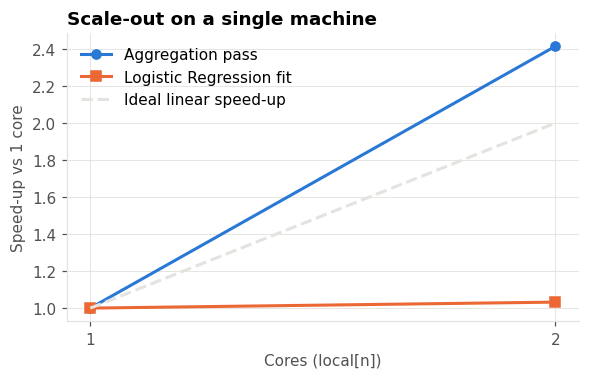

saved /content/drive/MyDrive/BDMLA/FlightDelay2025_outputs/figures/14_scaling_experiment.png
 cores  aggregation_s  lr_fit_s  aggregation_speedup  lr_speedup
     1           4.75     24.28                 1.00        1.00
     2           1.97     23.52                 2.41        1.03


In [41]:
if RUN_SCALING_EXPERIMENT:
    spark.catalog.clearCache()
    spark.stop()
    scale_rows = []
    core_options = sorted({1, max(1, N_CORES // 2), N_CORES})
    for cores in core_options:
        s = build_spark(master=f"local[{cores}]", app=f"scaling-{cores}")
        s.sparkContext.setLogLevel("ERROR")
        d = s.read.parquet(PREPARED)
        t0 = time.time()
        d.groupBy("ORIGIN", "MONTH").agg(F.avg("DELAYED"), F.count("*")).collect()
        agg_s = time.time() - t0
        sample = d.sample(fraction=0.2, seed=SEED).fillna(0, subset=NUMERIC_FEATURES)
        va = VectorAssembler(inputCols=NUMERIC_FEATURES, outputCol="features")
        sample = va.transform(sample).select("features", "DELAYED").cache(); sample.count()
        t0 = time.time()
        LogisticRegression(featuresCol="features", labelCol="DELAYED", maxIter=30).fit(sample)
        lr_s = time.time() - t0
        scale_rows.append({"cores": cores, "aggregation_s": agg_s, "lr_fit_s": lr_s})
        print(f"local[{cores}]: aggregation {agg_s:.1f}s, LR fit {lr_s:.1f}s")
        s.stop()
    scaling = pd.DataFrame(scale_rows)
    scaling["aggregation_speedup"] = scaling["aggregation_s"].iloc[0] / scaling["aggregation_s"]
    scaling["lr_speedup"] = scaling["lr_fit_s"].iloc[0] / scaling["lr_fit_s"]
    scaling.to_csv(f"{TABLE_DIR}/scaling_experiment.csv", index=False)

    fig, ax = plt.subplots(figsize=(6, 3.4))
    ax.plot(scaling["cores"], scaling["aggregation_speedup"], marker="o", color="#2a78d6", label="Aggregation pass")
    ax.plot(scaling["cores"], scaling["lr_speedup"], marker="s", color="#eb6834", label="Logistic Regression fit")
    ax.plot(scaling["cores"], scaling["cores"], linestyle="--", color=GRID, label="Ideal linear speed-up")
    ax.set_xlabel("Cores (local[n])"); ax.set_ylabel("Speed-up vs 1 core"); ax.set_xticks(scaling["cores"])
    ax.set_title("Scale-out on a single machine"); ax.legend()
    save_fig(fig, "14_scaling_experiment")
    print(scaling.round(2).to_string(index=False))
    with open(f"{OUTPUT_DIR}/report_placeholders.json") as fh:
        ph = json.load(fh)
    top = scaling.iloc[-1]
    ph.update({"SCALE_MAX_CORES": str(int(top["cores"])),
               "SCALE_AGG_1CORE_S": f"{scaling['aggregation_s'].iloc[0]:.1f}", "SCALE_AGG_NCORE_S": f"{top['aggregation_s']:.1f}",
               "SCALE_LR_1CORE_S": f"{scaling['lr_fit_s'].iloc[0]:.1f}", "SCALE_LR_NCORE_S": f"{top['lr_fit_s']:.1f}",
               "SCALE_AGG_SPEEDUP": f"{top['aggregation_speedup']:.2f}x", "SCALE_LR_SPEEDUP": f"{top['lr_speedup']:.2f}x"})
    with open(f"{OUTPUT_DIR}/report_placeholders.json", "w") as fh:
        json.dump(ph, fh, indent=2)
else:
    print("RUN_SCALING_EXPERIMENT is False, so this section is skipped.")

---
**End of notebook.** Figures are in `figures/`, tables in `tables/`, report values in `report_placeholders.json` and `run_summary.json`, and all outputs are zipped at `/content/work/bdmla_outputs.zip`.